In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, pearsonr, spearmanr
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from pandas.plotting import scatter_matrix, parallel_coordinates

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

In [3]:
df = pd.read_csv("recid.csv")

print("Dataset loaded successfully")
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

display(df.head(10))

Dataset loaded successfully
Total records: 1445
Total columns: 19


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449
5,6,1,0,0,1,0,0,1,0,0,1,12,0,277,13,79,79,1,4.369448
6,7,1,1,0,1,0,0,0,0,0,0,12,2,327,28,73,73,1,4.290460
7,8,1,0,0,1,0,1,1,1,0,2,10,3,314,34,73,73,1,4.290460
8,9,0,0,0,1,1,0,0,0,0,2,10,0,388,14,73,54,0,3.988984
9,10,1,0,0,1,1,1,1,0,0,0,11,2,430,32,73,60,0,4.094345


In [4]:
print("First 10 records")
display(df.head(10))

print("Last 10 records")
display(df.tail(10))

print("Dataset dimensions:", df.shape)

print("Column names")
print(df.columns.tolist())

print("Data types")
display(df.dtypes.to_frame("Data Type"))

print("Summary statistics")
display(df.describe(include="all").T)

First 10 records


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449
5,6,1,0,0,1,0,0,1,0,0,1,12,0,277,13,79,79,1,4.369448
6,7,1,1,0,1,0,0,0,0,0,0,12,2,327,28,73,73,1,4.290460
7,8,1,0,0,1,0,1,1,1,0,2,10,3,314,34,73,73,1,4.290460
8,9,0,0,0,1,1,0,0,0,0,2,10,0,388,14,73,54,0,3.988984
9,10,1,0,0,1,1,1,1,0,0,0,11,2,430,32,73,60,0,4.094345


Last 10 records


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
1435,1436,0,0,0,1,0,0,1,0,0,1,10,2,300,70,72,72,1,4.276666
1436,1437,1,0,1,1,0,0,0,0,0,0,12,1,299,11,76,76,1,4.330733
1437,1438,0,0,0,0,0,0,1,0,0,0,10,0,231,6,73,45,0,3.806663
1438,1439,0,0,0,0,0,0,1,0,0,0,9,2,290,34,70,5,0,1.609438
1439,1440,0,0,1,0,0,0,0,0,0,0,12,5,236,12,72,3,0,1.098612
1440,1441,0,1,1,1,0,0,0,0,0,0,12,0,393,8,80,80,1,4.382027
1441,1442,1,0,0,1,1,1,0,1,0,0,12,0,345,12,73,73,1,4.290460
1442,1443,1,0,0,0,0,0,1,0,0,0,11,3,264,36,81,81,1,4.394449
1443,1444,0,0,0,1,1,0,1,0,0,0,12,0,374,9,81,81,1,4.394449
1444,1445,0,0,0,1,0,0,0,0,0,0,8,2,252,13,72,72,1,4.276666


Dataset dimensions: (1445, 19)
Column names
['rownames', 'black', 'alcohol', 'drugs', 'super', 'married', 'felon', 'workprg', 'property', 'person', 'priors', 'educ', 'rules', 'age', 'tserved', 'follow', 'durat', 'cens', 'ldurat']
Data types


,Data Type
rownames,int64
black,int64
alcohol,int64
drugs,int64
super,int64
married,int64
felon,int64
workprg,int64
property,int64
person,int64


Summary statistics


,count,mean,std,min,25%,50%,75%,max
rownames,1445.0,723.000000,417.279882,1.0,362.000000,723.00000,1084.000000,1445.000000
black,1445.0,0.485121,0.499952,0.0,0.000000,0.00000,1.000000,1.000000
alcohol,1445.0,0.209689,0.407227,0.0,0.000000,0.00000,0.000000,1.000000
drugs,1445.0,0.241522,0.428154,0.0,0.000000,0.00000,0.000000,1.000000
super,1445.0,0.694118,0.460940,0.0,0.000000,1.00000,1.000000,1.000000
married,1445.0,0.255363,0.436216,0.0,0.000000,0.00000,1.000000,1.000000
felon,1445.0,0.314187,0.464352,0.0,0.000000,0.00000,1.000000,1.000000
workprg,1445.0,0.465052,0.498950,0.0,0.000000,0.00000,1.000000,1.000000
property,1445.0,0.254671,0.435827,0.0,0.000000,0.00000,1.000000,1.000000
person,1445.0,0.053287,0.224683,0.0,0.000000,0.00000,0.000000,1.000000


In [5]:
numcols = df.select_dtypes(include=np.number).columns.tolist()
catcols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical variables")
print(numcols)

print("\nCategorical variables")
print(catcols)

print("\nNumber of numerical variables:", len(numcols))
print("Number of categorical variables:", len(catcols))

Numerical variables
['rownames', 'black', 'alcohol', 'drugs', 'super', 'married', 'felon', 'workprg', 'property', 'person', 'priors', 'educ', 'rules', 'age', 'tserved', 'follow', 'durat', 'cens', 'ldurat']

Categorical variables
[]

Number of numerical variables: 19
Number of categorical variables: 0


In [6]:
print("Missing values in each column")
display(df.isnull().sum().to_frame("Missing Values"))

print("Total missing values:", df.isnull().sum().sum())

Missing values in each column


,Missing Values
rownames,0
black,0
alcohol,0
drugs,0
super,0
married,0
felon,0
workprg,0
property,0
person,0


Total missing values: 0


In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    plt.figure(figsize=(10, 5))
    missing.plot(kind="bar")
    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset.")

No missing values found in the dataset.


In [8]:
missingrows = df[df.isnull().any(axis=1)]

print("Number of rows containing missing values:", len(missingrows))
display(missingrows.head(10))

Number of rows containing missing values: 0


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat


In [9]:
data = df.copy()

numcols = data.select_dtypes(include=np.number).columns

for col in numcols:
    data[col] = data[col].fillna(data[col].mean())

display(data.head(10))
print("Remaining missing values:", data.isnull().sum().sum())

,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449
5,6,1,0,0,1,0,0,1,0,0,1,12,0,277,13,79,79,1,4.369448
6,7,1,1,0,1,0,0,0,0,0,0,12,2,327,28,73,73,1,4.290460
7,8,1,0,0,1,0,1,1,1,0,2,10,3,314,34,73,73,1,4.290460
8,9,0,0,0,1,1,0,0,0,0,2,10,0,388,14,73,54,0,3.988984
9,10,1,0,0,1,1,1,1,0,0,0,11,2,430,32,73,60,0,4.094345


Remaining missing values: 0


In [10]:
data = df.copy()

numcols = data.select_dtypes(include=np.number).columns

for col in numcols:
    data[col] = data[col].fillna(data[col].median())

display(data.head(10))
print("Remaining missing values:", data.isnull().sum().sum())

,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449
5,6,1,0,0,1,0,0,1,0,0,1,12,0,277,13,79,79,1,4.369448
6,7,1,1,0,1,0,0,0,0,0,0,12,2,327,28,73,73,1,4.290460
7,8,1,0,0,1,0,1,1,1,0,2,10,3,314,34,73,73,1,4.290460
8,9,0,0,0,1,1,0,0,0,0,2,10,0,388,14,73,54,0,3.988984
9,10,1,0,0,1,1,1,1,0,0,0,11,2,430,32,73,60,0,4.094345


Remaining missing values: 0


Selected column: rownames
Mean: 723.0
Median: 723.0


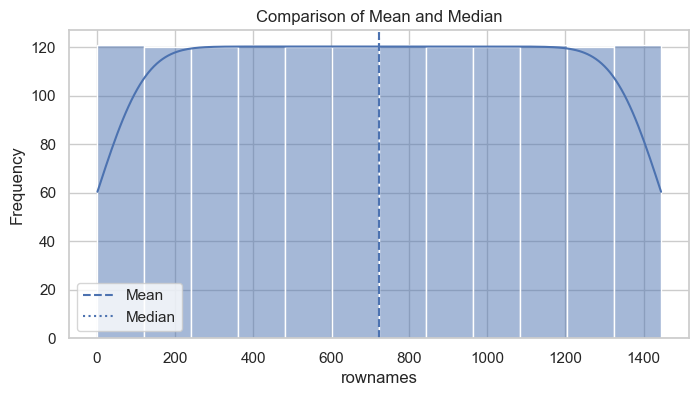

In [11]:
col = numcols[0]

meanvalue = df[col].mean()
medianvalue = df[col].median()

print("Selected column:", col)
print("Mean:", meanvalue)
print("Median:", medianvalue)

plt.figure(figsize=(8, 4))
sns.histplot(df[col].dropna(), kde=True)
plt.axvline(meanvalue, linestyle="--", label="Mean")
plt.axvline(medianvalue, linestyle=":", label="Median")
plt.title("Comparison of Mean and Median")
plt.xlabel(col)
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [12]:
data = df.copy()

catcols = data.select_dtypes(exclude=np.number).columns

for col in catcols:
    modes = data[col].mode()
    if not modes.empty:
        data[col] = data[col].fillna(modes.iloc[0])

display(data.head(10))

,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449
5,6,1,0,0,1,0,0,1,0,0,1,12,0,277,13,79,79,1,4.369448
6,7,1,1,0,1,0,0,0,0,0,0,12,2,327,28,73,73,1,4.290460
7,8,1,0,0,1,0,1,1,1,0,2,10,3,314,34,73,73,1,4.290460
8,9,0,0,0,1,1,0,0,0,0,2,10,0,388,14,73,54,0,3.988984
9,10,1,0,0,1,1,1,1,0,0,0,11,2,430,32,73,60,0,4.094345


In [13]:
forwarddata = df.ffill()
backwarddata = df.bfill()

print("Forward fill")
display(forwarddata.head(10))

print("Backward fill")
display(backwarddata.head(10))

Forward fill


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449
5,6,1,0,0,1,0,0,1,0,0,1,12,0,277,13,79,79,1,4.369448
6,7,1,1,0,1,0,0,0,0,0,0,12,2,327,28,73,73,1,4.290460
7,8,1,0,0,1,0,1,1,1,0,2,10,3,314,34,73,73,1,4.290460
8,9,0,0,0,1,1,0,0,0,0,2,10,0,388,14,73,54,0,3.988984
9,10,1,0,0,1,1,1,1,0,0,0,11,2,430,32,73,60,0,4.094345


Backward fill


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449
5,6,1,0,0,1,0,0,1,0,0,1,12,0,277,13,79,79,1,4.369448
6,7,1,1,0,1,0,0,0,0,0,0,12,2,327,28,73,73,1,4.290460
7,8,1,0,0,1,0,1,1,1,0,2,10,3,314,34,73,73,1,4.290460
8,9,0,0,0,1,1,0,0,0,0,2,10,0,388,14,73,54,0,3.988984
9,10,1,0,0,1,1,1,1,0,0,0,11,2,430,32,73,60,0,4.094345


In [14]:
data = df.copy()

for col in data.columns:
    if pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].fillna(0)
    else:
        data[col] = data[col].fillna("Unknown")

print("Remaining missing values:", data.isnull().sum().sum())
display(data.head(10))

Remaining missing values: 0


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449
5,6,1,0,0,1,0,0,1,0,0,1,12,0,277,13,79,79,1,4.369448
6,7,1,1,0,1,0,0,0,0,0,0,12,2,327,28,73,73,1,4.290460
7,8,1,0,0,1,0,1,1,1,0,2,10,3,314,34,73,73,1,4.290460
8,9,0,0,0,1,1,0,0,0,0,2,10,0,388,14,73,54,0,3.988984
9,10,1,0,0,1,1,1,1,0,0,0,11,2,430,32,73,60,0,4.094345


In [15]:
print("Duplicate records:", df.duplicated().sum())

duplicates = df[df.duplicated(keep=False)]

print("Duplicate rows")
display(duplicates.head(10))

data = df.drop_duplicates()

print("Original shape:", df.shape)
print("Shape after removing duplicates:", data.shape)

Duplicate records: 0
Duplicate rows


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat


Original shape: (1445, 19)
Shape after removing duplicates: (1445, 19)


In [16]:
data = df.copy()

binarycols = [
    col for col in data.columns
    if data[col].dropna().nunique() == 2
]

print("Binary columns:", binarycols)

for col in binarycols:
    data[col] = data[col].astype("category")

display(data.dtypes.to_frame("Data Type"))

Binary columns: ['black', 'alcohol', 'drugs', 'super', 'married', 'felon', 'workprg', 'property', 'person', 'cens']


,Data Type
rownames,int64
black,category
alcohol,category
drugs,category
super,category
married,category
felon,category
workprg,category
property,category
person,category


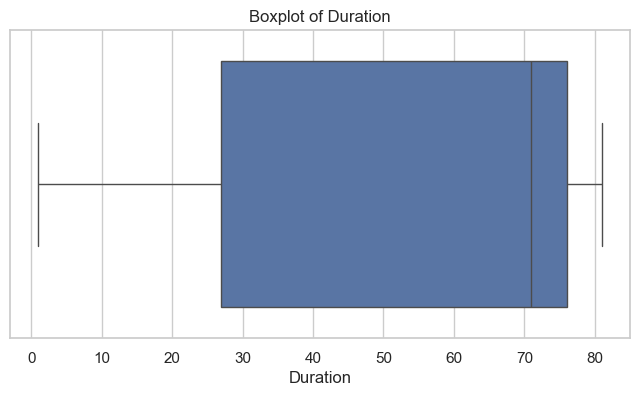

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["durat"])
plt.title("Boxplot of Duration")
plt.xlabel("Duration")
plt.show()

In [18]:
col = "durat"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("First Quartile:", q1)
print("Third Quartile:", q3)
print("IQR:", iqr)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Number of Outliers:", len(outliers))

display(outliers.head(10))

First Quartile: 27.0
Third Quartile: 76.0
IQR: 49.0
Lower Limit: -46.5
Upper Limit: 149.5
Number of Outliers: 0


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat


Original number of records: 1445
Records after outlier removal: 1445
Records removed: 0


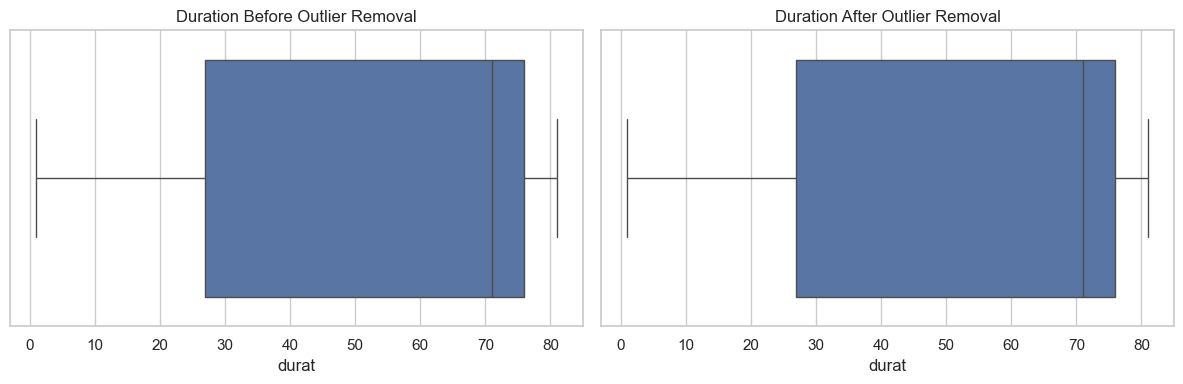

In [19]:
cleaned = df[df["durat"].between(lower, upper)].copy()

print("Original number of records:", len(df))
print("Records after outlier removal:", len(cleaned))
print("Records removed:", len(df) - len(cleaned))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df["durat"], ax=ax[0])
ax[0].set_title("Duration Before Outlier Removal")

sns.boxplot(x=cleaned["durat"], ax=ax[1])
ax[1].set_title("Duration After Outlier Removal")

plt.tight_layout()
plt.show()

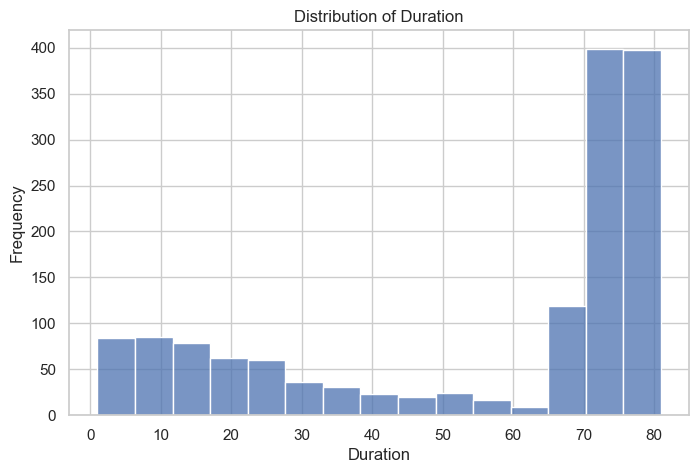

In [20]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="durat", bins=15)
plt.title("Distribution of Duration")
plt.xlabel("Duration")
plt.ylabel("Frequency")
plt.show()

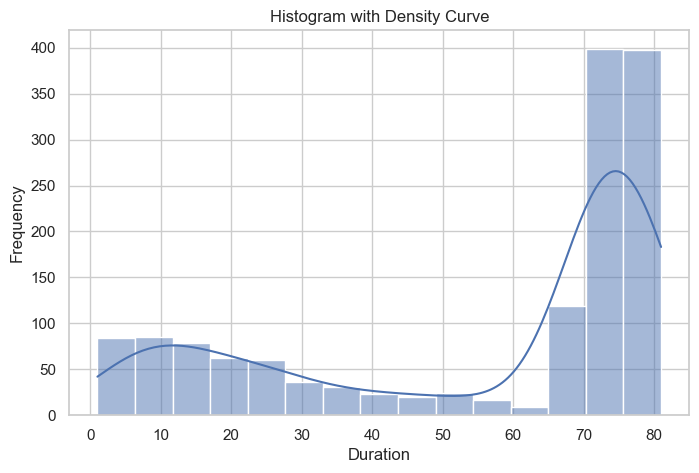

In [21]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="durat", bins=15, kde=True)
plt.title("Histogram with Density Curve")
plt.xlabel("Duration")
plt.ylabel("Frequency")
plt.show()

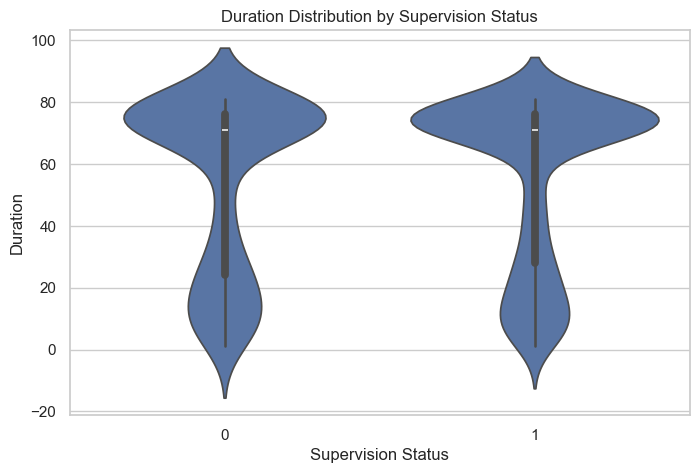

In [22]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="super", y="durat")
plt.title("Duration Distribution by Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Duration")
plt.show()

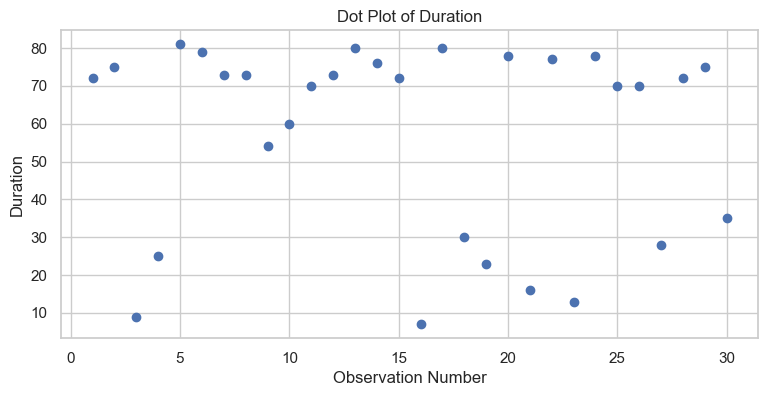

In [23]:
values = df["durat"].dropna().head(30)

plt.figure(figsize=(9, 4))
plt.scatter(range(1, len(values) + 1), values)
plt.title("Dot Plot of Duration")
plt.xlabel("Observation Number")
plt.ylabel("Duration")
plt.show()

In [24]:
frequency = df["super"].value_counts().sort_index()

print("Frequency Distribution")
display(frequency.to_frame("Frequency"))

Frequency Distribution


,Frequency
super,
0,442
1,1003


In [25]:
comparison = pd.DataFrame({
    "Frequency": frequency,
    "Proportion": frequency / frequency.sum(),
    "Percentage": frequency / frequency.sum() * 100
})

display(comparison)

,Frequency,Proportion,Percentage
super,,,
0,442,0.305882,30.588235
1,1003,0.694118,69.411765


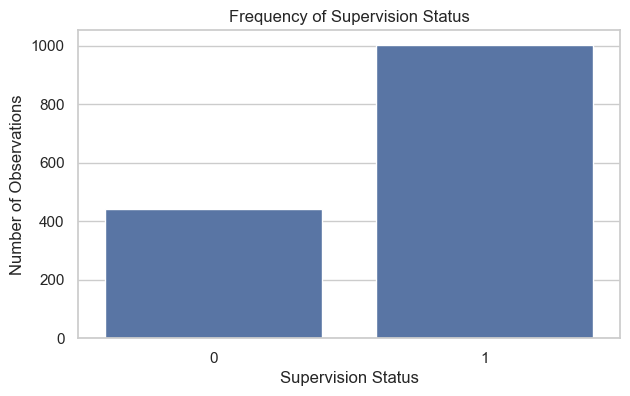

In [26]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="super")
plt.title("Frequency of Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Number of Observations")
plt.show()

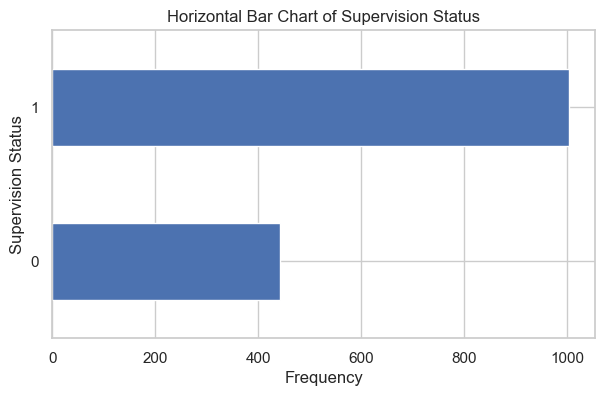

In [27]:
frequency.sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Horizontal Bar Chart of Supervision Status")
plt.xlabel("Frequency")
plt.ylabel("Supervision Status")
plt.show()

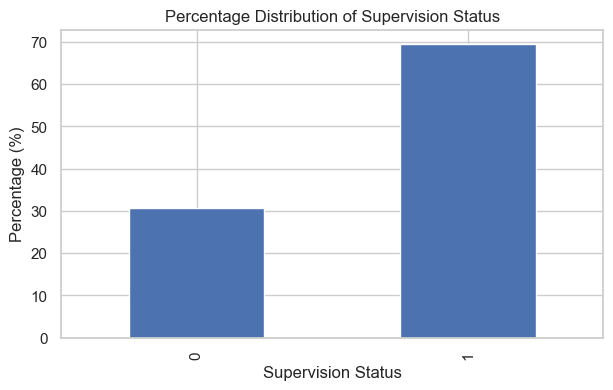

In [28]:
percentage = frequency / frequency.sum() * 100

percentage.plot(kind="bar", figsize=(7, 4))
plt.title("Percentage Distribution of Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Percentage (%)")
plt.show()

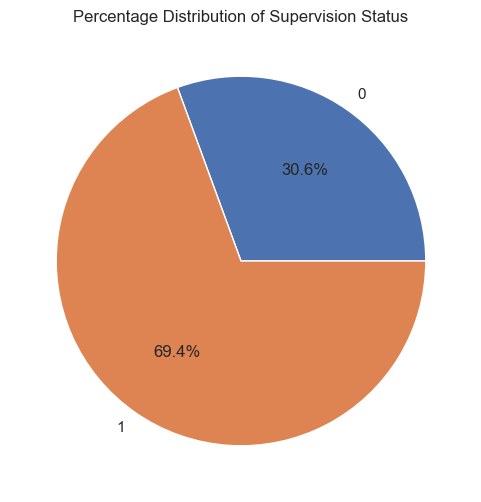

In [29]:
frequency.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6),
    ylabel=""
)

plt.title("Percentage Distribution of Supervision Status")
plt.show()

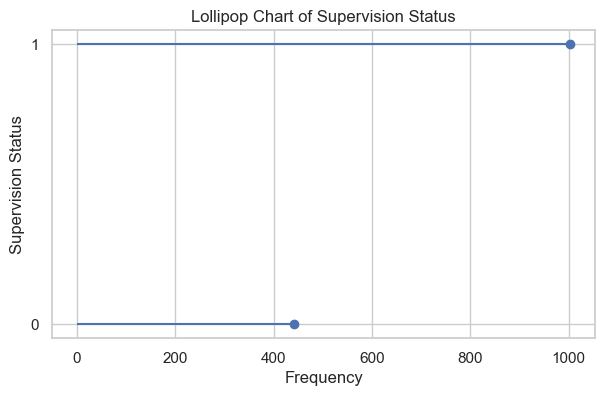

In [30]:
plt.figure(figsize=(7, 4))

plt.hlines(
    y=frequency.index.astype(str),
    xmin=0,
    xmax=frequency.values
)

plt.plot(
    frequency.values,
    frequency.index.astype(str),
    "o"
)

plt.title("Lollipop Chart of Supervision Status")
plt.xlabel("Frequency")
plt.ylabel("Supervision Status")
plt.show()

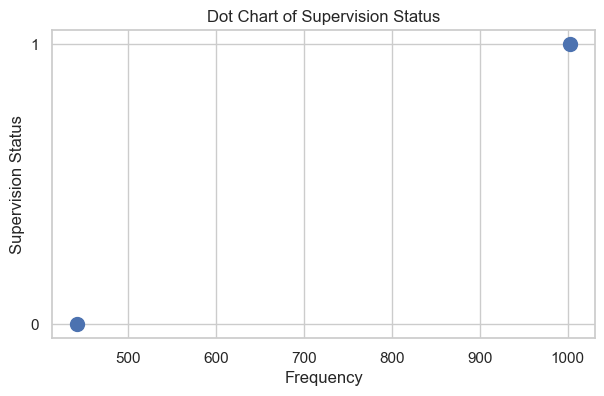

In [31]:
plt.figure(figsize=(7, 4))

plt.scatter(
    frequency.values,
    frequency.index.astype(str),
    s=100
)

plt.title("Dot Chart of Supervision Status")
plt.xlabel("Frequency")
plt.ylabel("Supervision Status")
plt.show()

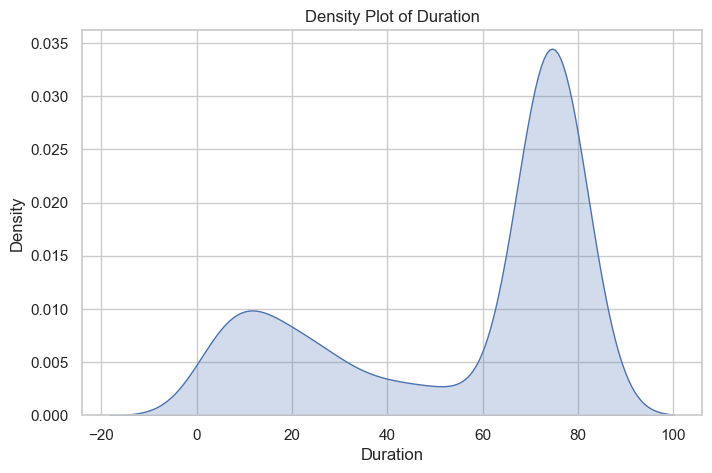

In [32]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="durat", fill=True)
plt.title("Density Plot of Duration")
plt.xlabel("Duration")
plt.ylabel("Density")
plt.show()

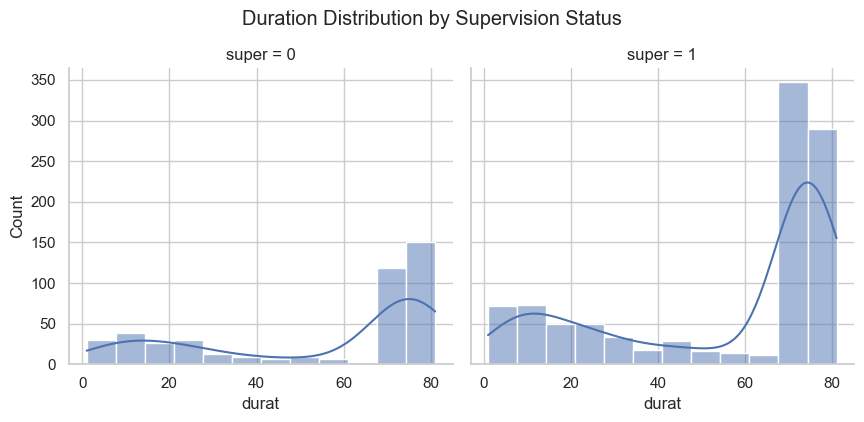

In [33]:
sns.displot(
    data=df,
    x="durat",
    col="super",
    kde=True,
    height=4,
    aspect=1.1
)

plt.suptitle("Duration Distribution by Supervision Status", y=1.05)
plt.show()

In [34]:
cat1 = "super"
cat2 = "married"
num1 = "age"
num2 = "priors"
num3 = "durat"

print("Categorical variables:", cat1, cat2)
print("Numerical variables:", num1, num2, num3)

Categorical variables: super married
Numerical variables: age priors durat


In [35]:
table = pd.crosstab(df[cat1], df[cat2])

print("Contingency Table")
display(table)

Contingency Table


married,0,1
super,,
0,354,88
1,722,281


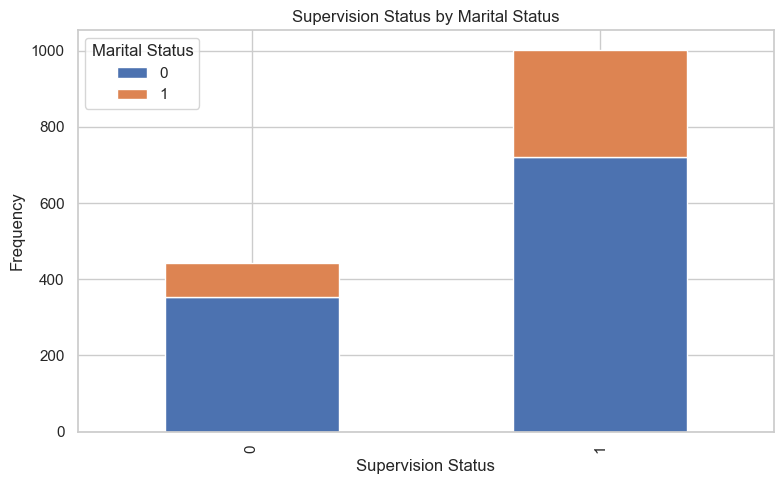

In [36]:
table.plot(kind="bar", stacked=True, figsize=(8, 5))

plt.title("Supervision Status by Marital Status")
plt.xlabel("Supervision Status")
plt.ylabel("Frequency")
plt.legend(title="Marital Status")
plt.tight_layout()
plt.show()

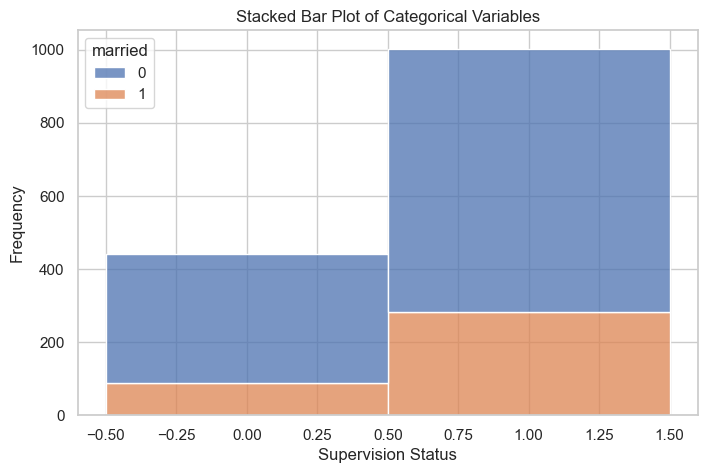

In [37]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x=cat1,
    hue=cat2,
    multiple="stack",
    discrete=True
)

plt.title("Stacked Bar Plot of Categorical Variables")
plt.xlabel("Supervision Status")
plt.ylabel("Frequency")
plt.show()

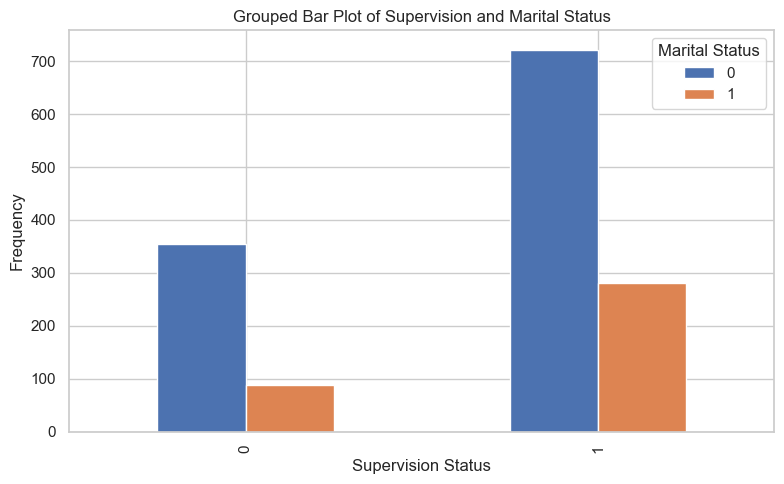

In [38]:
table.plot(kind="bar", stacked=False, figsize=(8, 5))

plt.title("Grouped Bar Plot of Supervision and Marital Status")
plt.xlabel("Supervision Status")
plt.ylabel("Frequency")
plt.legend(title="Marital Status")
plt.tight_layout()
plt.show()

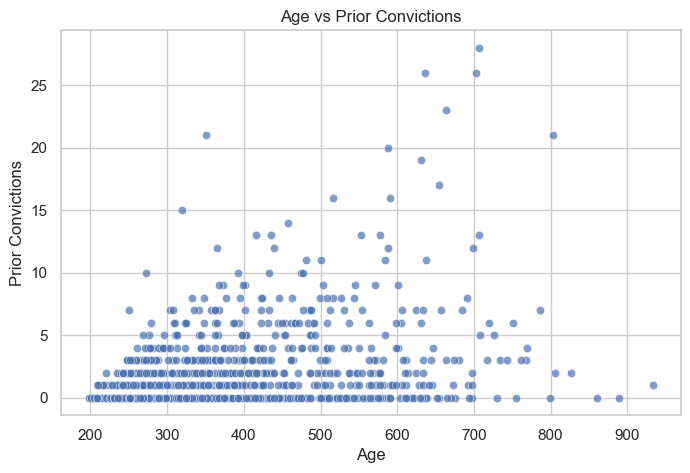

In [39]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x=num1, y=num2, alpha=0.7)

plt.title("Age vs Prior Convictions")
plt.xlabel("Age")
plt.ylabel("Prior Convictions")
plt.show()

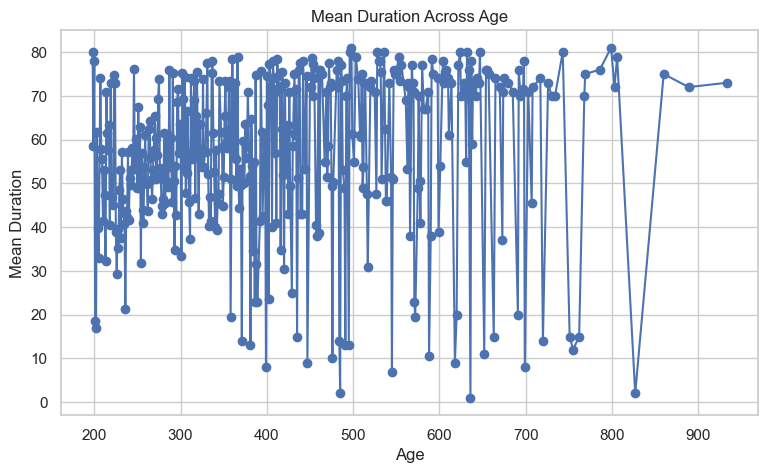

In [40]:
trend = df.groupby(num1, as_index=False)[num3].mean().sort_values(num1)

plt.figure(figsize=(9, 5))

plt.plot(trend[num1], trend[num3], marker="o")

plt.title("Mean Duration Across Age")
plt.xlabel("Age")
plt.ylabel("Mean Duration")
plt.show()

,age,priors,durat
age,1.000000,0.420523,0.097341
priors,0.420523,1.000000,-0.139440
durat,0.097341,-0.139440,1.000000


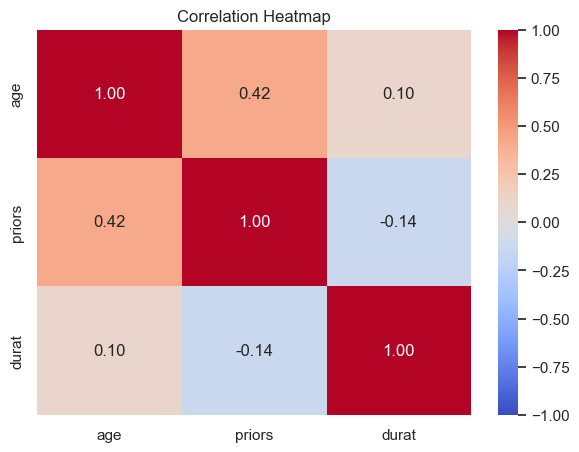

In [41]:
correlation = df[[num1, num2, num3]].corr()

display(correlation)

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

,Mean Age
super,
0,353.192308
1,342.017946


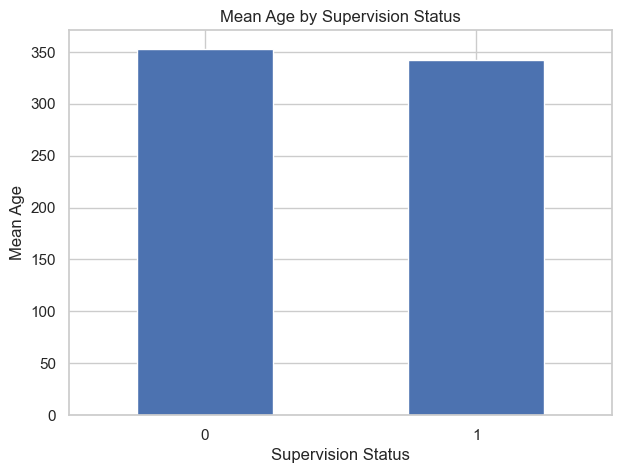

In [42]:
comparison = df.groupby(cat1)[num1].mean()

display(comparison.to_frame("Mean Age"))

comparison.plot(kind="bar", figsize=(7, 5))

plt.title("Mean Age by Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Mean Age")
plt.xticks(rotation=0)
plt.show()

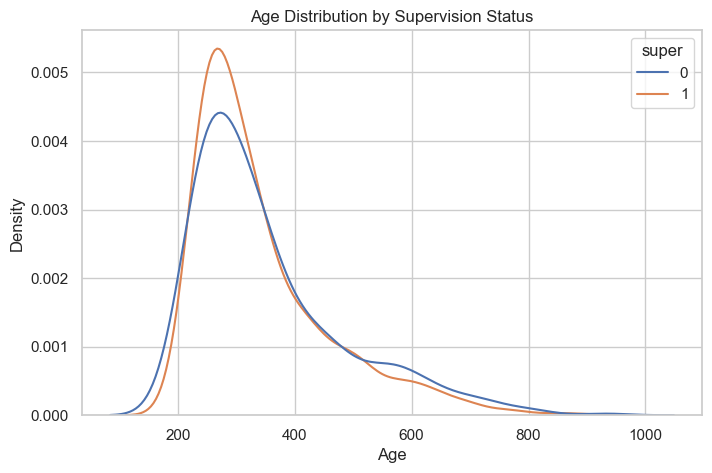

In [43]:
plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=df,
    x=num1,
    hue=cat1,
    common_norm=False
)

plt.title("Age Distribution by Supervision Status")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()

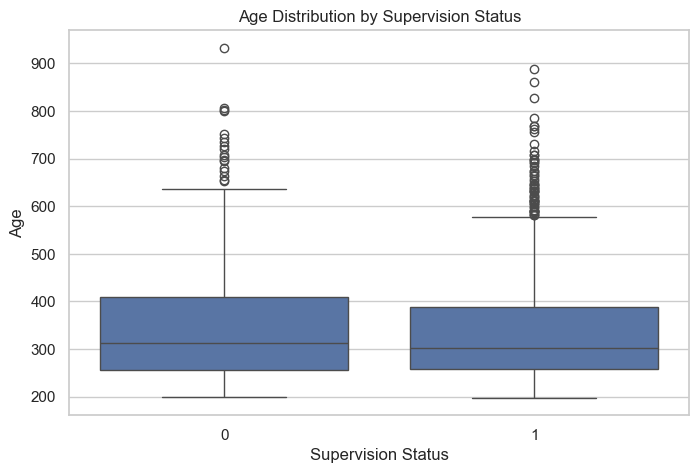

In [44]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x=cat1, y=num1)

plt.title("Age Distribution by Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Age")
plt.show()

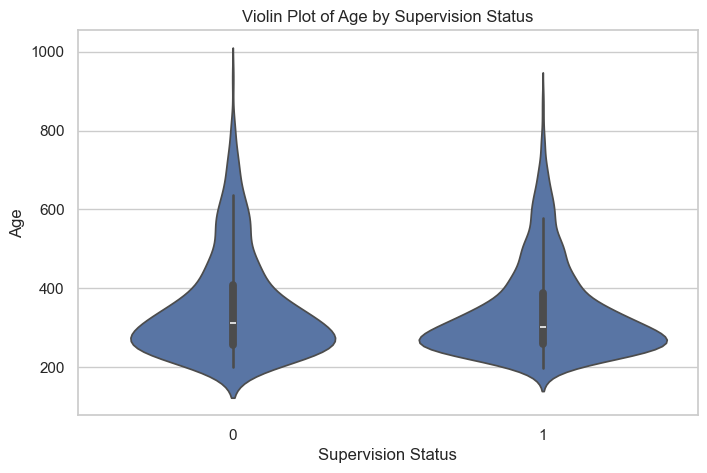

In [45]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=df, x=cat1, y=num1)

plt.title("Violin Plot of Age by Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Age")
plt.show()

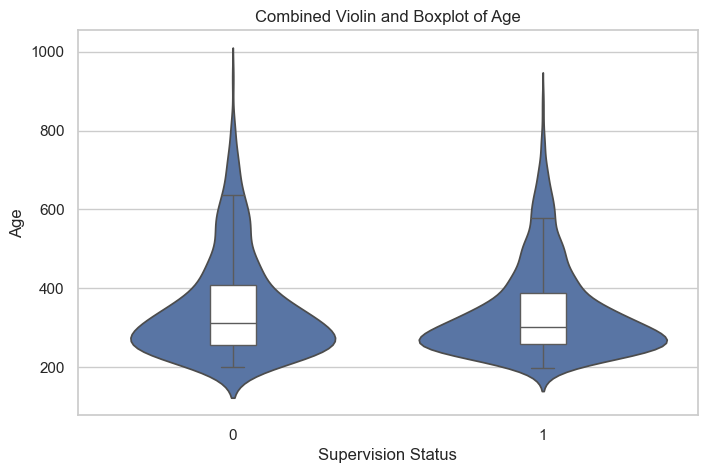

In [46]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=df, x=cat1, y=num1, inner=None)
sns.boxplot(
    data=df,
    x=cat1,
    y=num1,
    width=0.15,
    showfliers=False,
    boxprops={"facecolor": "white"}
)

plt.title("Combined Violin and Boxplot of Age")
plt.xlabel("Supervision Status")
plt.ylabel("Age")
plt.show()

In [47]:
numcols = df.select_dtypes(include=np.number).columns.tolist()
catcols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Variables")
print(numcols)

print("\nCategorical Variables")
print(catcols)

display(df.head())

Numerical Variables
['rownames', 'black', 'alcohol', 'drugs', 'super', 'married', 'felon', 'workprg', 'property', 'person', 'priors', 'educ', 'rules', 'age', 'tserved', 'follow', 'durat', 'cens', 'ldurat']

Categorical Variables
[]


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
0,1,0,1,0,1,1,0,1,0,0,0,7,2,441,30,72,72,1,4.276666
1,2,1,0,0,1,0,1,1,1,0,0,12,0,307,19,75,75,1,4.317488
2,3,0,0,0,0,0,0,1,1,0,0,9,5,262,27,81,9,0,2.197225
3,4,0,0,1,1,0,1,1,1,0,2,9,3,253,38,76,25,0,3.218876
4,5,0,0,1,1,0,0,0,0,0,0,9,0,244,4,81,81,1,4.394449


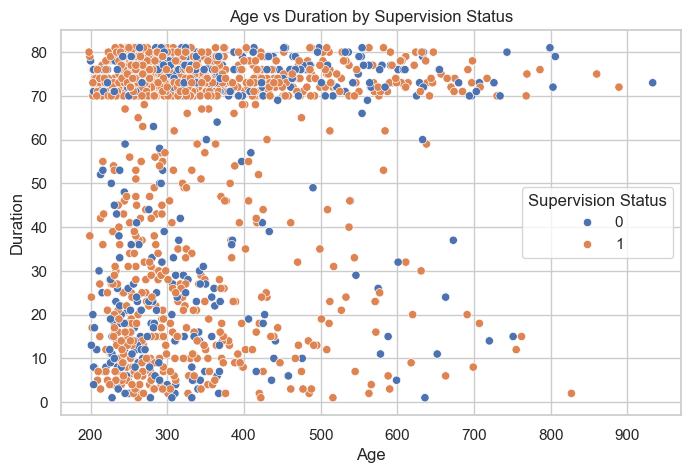

In [48]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="durat",
    hue="super"
)

plt.title("Age vs Duration by Supervision Status")
plt.xlabel("Age")
plt.ylabel("Duration")
plt.legend(title="Supervision Status")
plt.show()

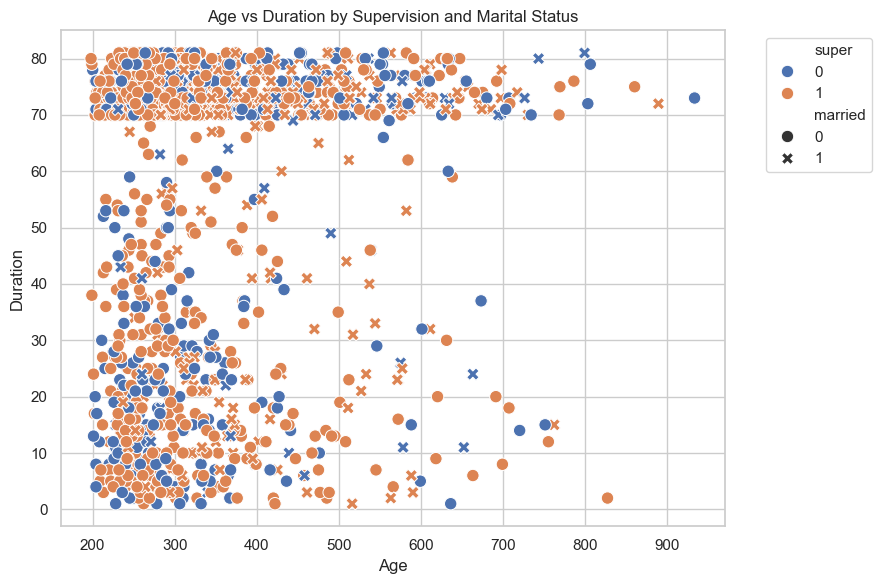

In [49]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="durat",
    hue="super",
    style="married",
    s=80
)

plt.title("Age vs Duration by Supervision and Marital Status")
plt.xlabel("Age")
plt.ylabel("Duration")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

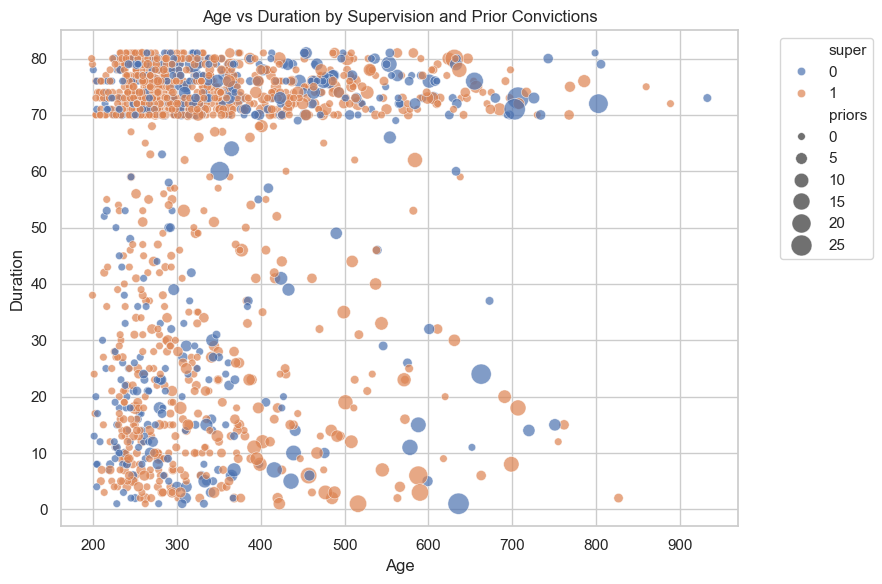

In [50]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="durat",
    hue="super",
    size="priors",
    sizes=(30, 250),
    alpha=0.7
)

plt.title("Age vs Duration by Supervision and Prior Convictions")
plt.xlabel("Age")
plt.ylabel("Duration")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

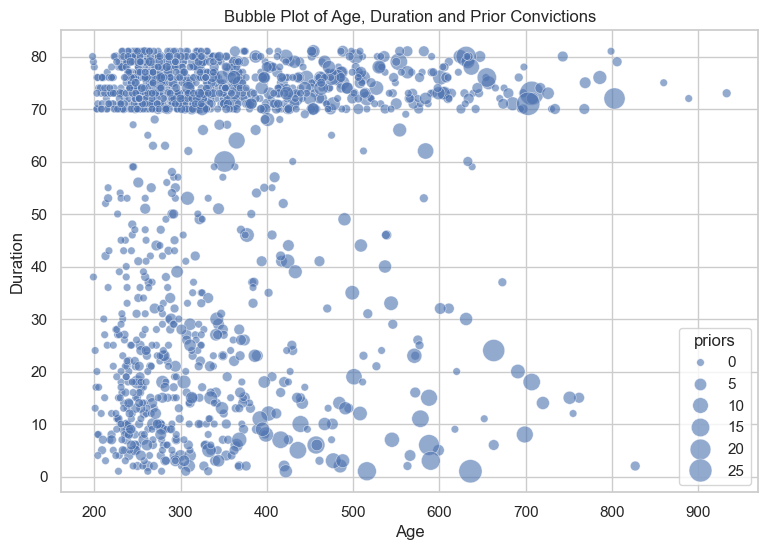

In [51]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="durat",
    size="priors",
    sizes=(30, 300),
    alpha=0.6,
    legend=True
)

plt.title("Bubble Plot of Age, Duration and Prior Convictions")
plt.xlabel("Age")
plt.ylabel("Duration")
plt.show()

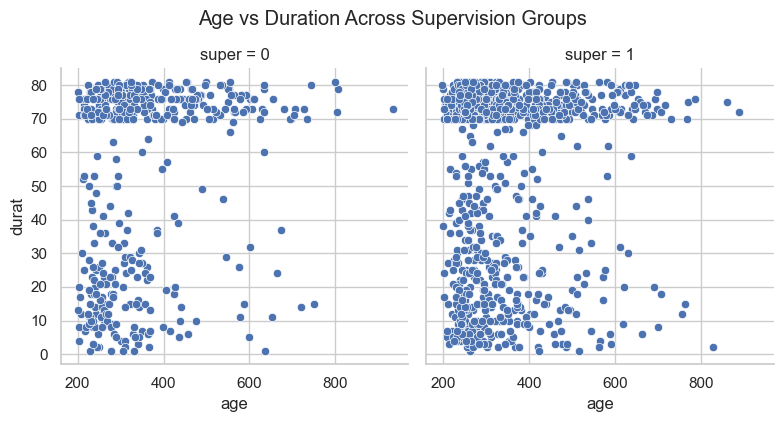

In [52]:
sns.relplot(
    data=df,
    x="age",
    y="durat",
    col="super",
    kind="scatter",
    height=4,
    aspect=1
)

plt.suptitle("Age vs Duration Across Supervision Groups", y=1.05)
plt.show()

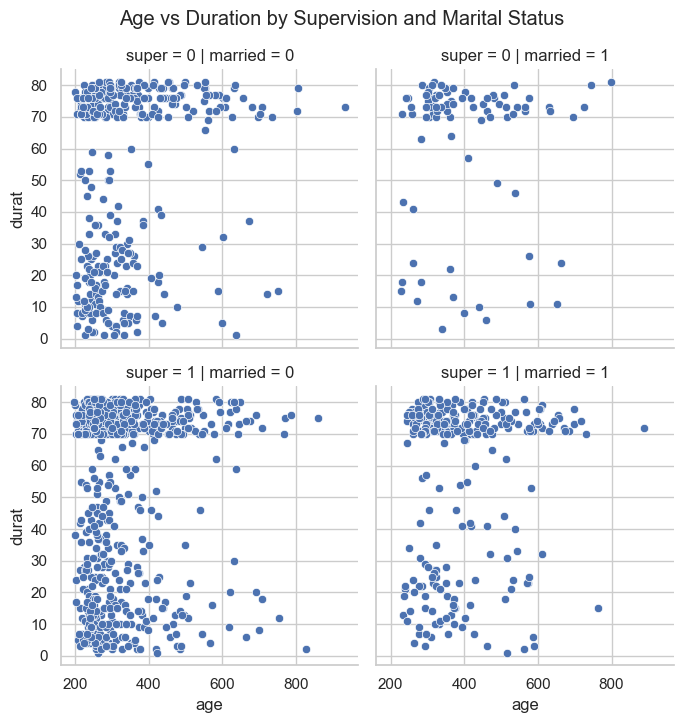

In [53]:
sns.relplot(
    data=df,
    x="age",
    y="durat",
    row="super",
    col="married",
    kind="scatter",
    height=3.5,
    aspect=1
)

plt.suptitle("Age vs Duration by Supervision and Marital Status", y=1.03)
plt.show()

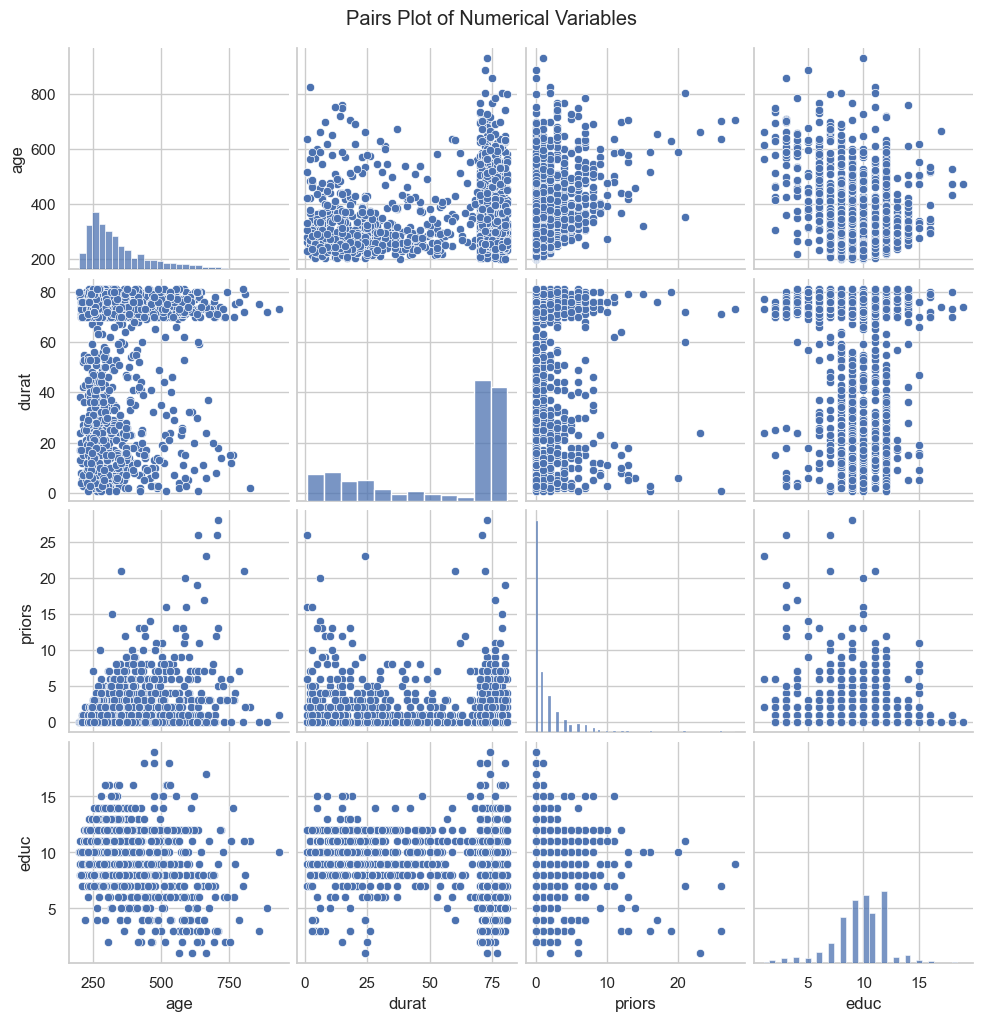

In [54]:
pairdata = df[["age", "durat", "priors", "educ"]].dropna()

sns.pairplot(pairdata, diag_kind="hist")

plt.suptitle("Pairs Plot of Numerical Variables", y=1.02)
plt.show()

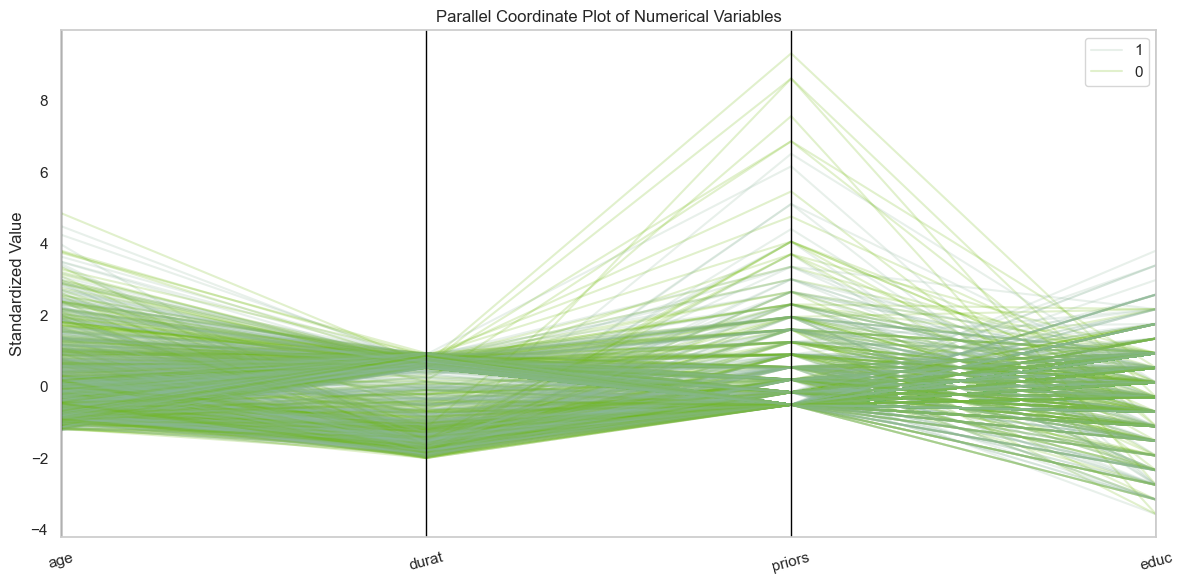

In [55]:
paralleldata = df[["age", "durat", "priors", "educ", "super"]].dropna().copy()

paralleldata["super"] = paralleldata["super"].astype(str)

paralleldata[["age", "durat", "priors", "educ"]] = StandardScaler().fit_transform(
    paralleldata[["age", "durat", "priors", "educ"]]
)

plt.figure(figsize=(12, 6))

parallel_coordinates(
    paralleldata,
    class_column="super",
    alpha=0.2
)

plt.title("Parallel Coordinate Plot of Numerical Variables")
plt.ylabel("Standardized Value")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [56]:
x = df["durat"].dropna()

summary = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Range",
        "Variance",
        "Standard Deviation",
        "IQR",
        "Skewness",
        "Kurtosis"
    ],
    "Value": [
        x.mean(),
        x.median(),
        x.min(),
        x.max(),
        x.max() - x.min(),
        x.var(),
        x.std(),
        x.quantile(0.75) - x.quantile(0.25),
        skew(x),
        kurtosis(x)
    ]
})

display(summary)

,Statistic,Value
0,Mean,55.372318
1,Median,71.000000
2,Minimum,1.000000
3,Maximum,81.000000
4,Range,80.000000
5,Variance,745.171532
6,Standard Deviation,27.297830
7,IQR,49.000000
8,Skewness,-0.818263
9,Kurtosis,-1.049222


In [57]:
x = df["durat"].dropna()

summary = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Range",
        "Variance",
        "Standard Deviation",
        "IQR",
        "Skewness",
        "Kurtosis"
    ],
    "Value": [
        x.mean(),
        x.median(),
        x.min(),
        x.max(),
        x.max() - x.min(),
        x.var(),
        x.std(),
        x.quantile(0.75) - x.quantile(0.25),
        skew(x),
        kurtosis(x)
    ]
})

display(summary)

,Statistic,Value
0,Mean,55.372318
1,Median,71.000000
2,Minimum,1.000000
3,Maximum,81.000000
4,Range,80.000000
5,Variance,745.171532
6,Standard Deviation,27.297830
7,IQR,49.000000
8,Skewness,-0.818263
9,Kurtosis,-1.049222


In [58]:
frequency = df["super"].value_counts().sort_index()

relative = frequency / frequency.sum()

result = pd.DataFrame({
    "Frequency": frequency,
    "Relative Frequency": relative,
    "Percentage": relative * 100
})

display(result)

,Frequency,Relative Frequency,Percentage
super,,,
0,442,0.305882,30.588235
1,1003,0.694118,69.411765


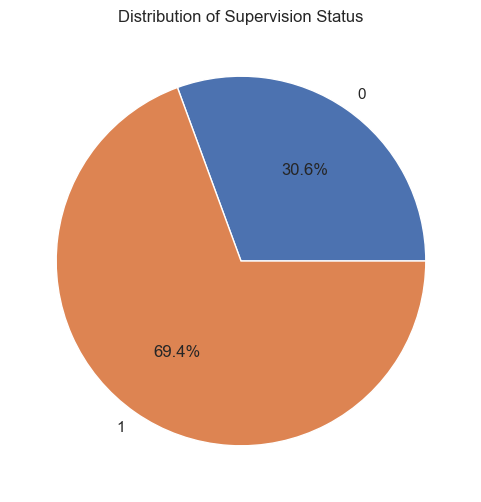

In [59]:
frequency.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6),
    ylabel=""
)

plt.title("Distribution of Supervision Status")
plt.show()

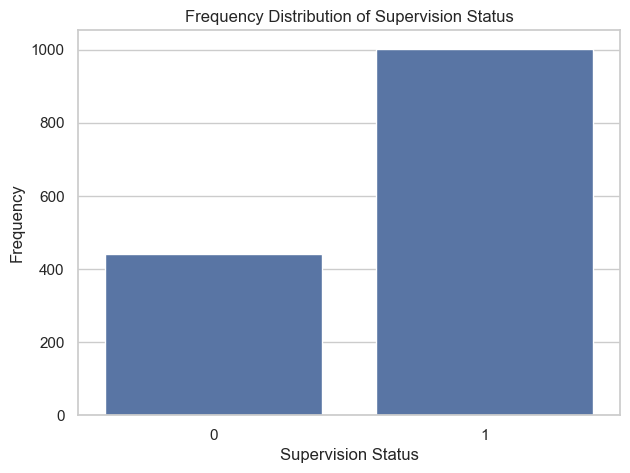

In [60]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="super")

plt.title("Frequency Distribution of Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Frequency")
plt.show()

In [61]:
intervals = pd.cut(df["durat"], bins=10)

distribution = intervals.value_counts().sort_index()

display(distribution.to_frame("Frequency"))

,Frequency
durat,
"(0.92, 9.0]",136
"(9.0, 17.0]",121
"(17.0, 25.0]",94
"(25.0, 33.0]",61
"(33.0, 41.0]",38
"(41.0, 49.0]",34
"(49.0, 57.0]",31
"(57.0, 65.0]",17
"(65.0, 73.0]",400


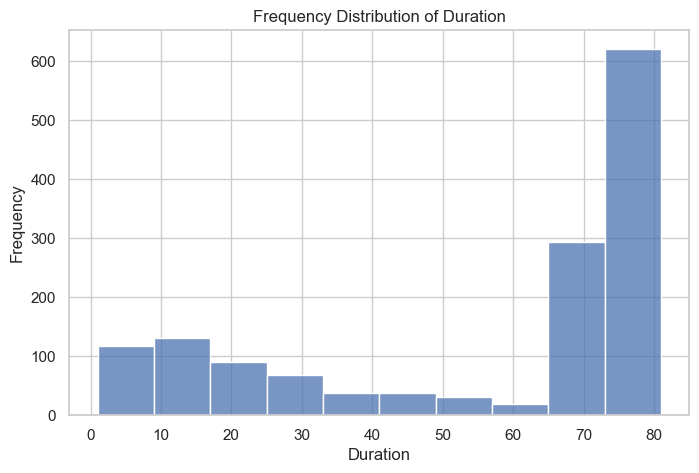

In [62]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="durat", bins=10)

plt.title("Frequency Distribution of Duration")
plt.xlabel("Duration")
plt.ylabel("Frequency")
plt.show()

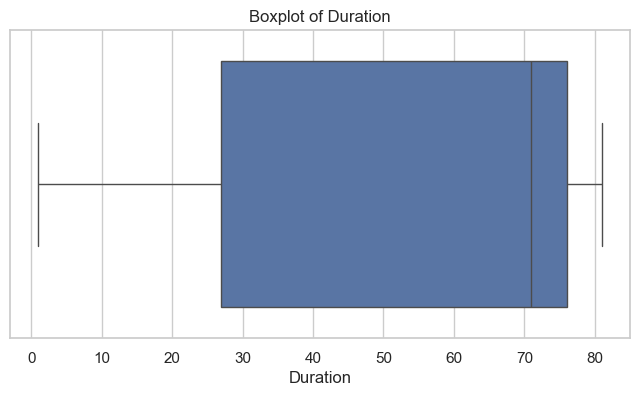

In [63]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["durat"])

plt.title("Boxplot of Duration")
plt.xlabel("Duration")
plt.show()

In [64]:
table = pd.crosstab(df["super"], df["married"])

print("Contingency Table")
display(table)

print("Row Percentages")
display(pd.crosstab(df["super"], df["married"], normalize="index") * 100)

print("Column Percentages")
display(pd.crosstab(df["super"], df["married"], normalize="columns") * 100)

Contingency Table


married,0,1
super,,
0,354,88
1,722,281


Row Percentages


married,0,1
super,,
0,80.090498,19.909502
1,71.984048,28.015952


Column Percentages


married,0,1
super,,
0,32.899628,23.848238
1,67.100372,76.151762


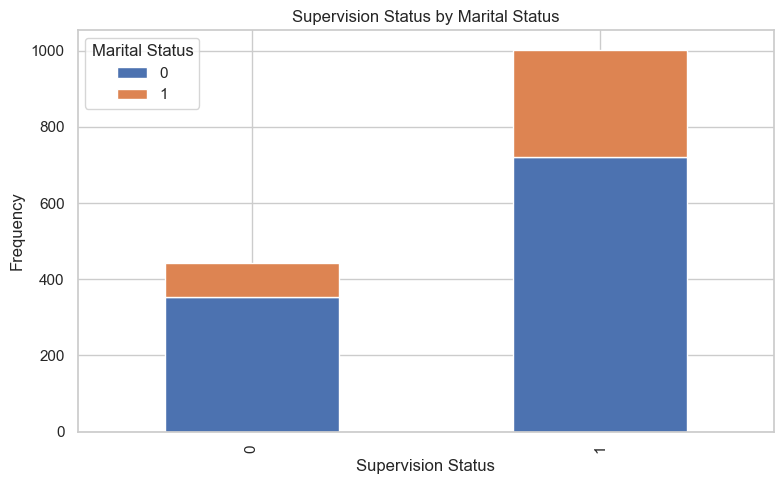

In [65]:
table.plot(kind="bar", stacked=True, figsize=(8, 5))

plt.title("Supervision Status by Marital Status")
plt.xlabel("Supervision Status")
plt.ylabel("Frequency")
plt.legend(title="Marital Status")
plt.tight_layout()
plt.show()

In [66]:
grouped = df.groupby("super", observed=False)["durat"].agg(
    ["mean", "median", "std"]
)

display(grouped)

,mean,median,std
super,,,
0,54.386878,71.0,28.008131
1,55.806580,71.0,26.981632


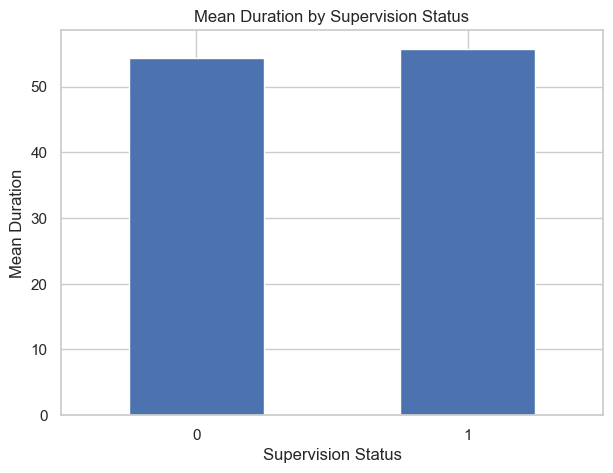

In [67]:
grouped["mean"].plot(kind="bar", figsize=(7, 5))

plt.title("Mean Duration by Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Mean Duration")
plt.xticks(rotation=0)
plt.show()

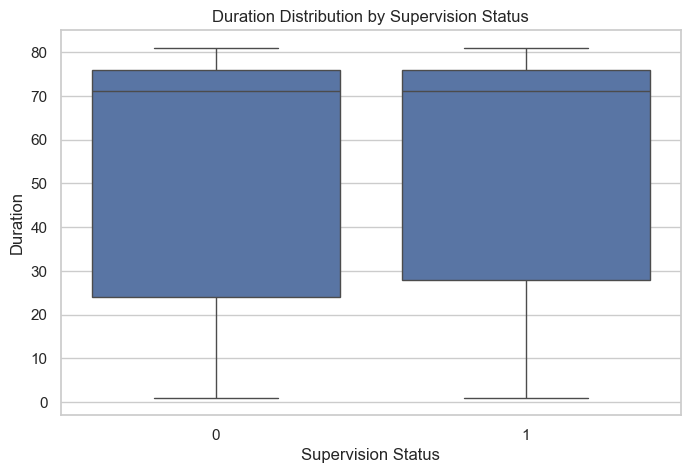

In [68]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="super", y="durat")

plt.title("Duration Distribution by Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Duration")
plt.show()

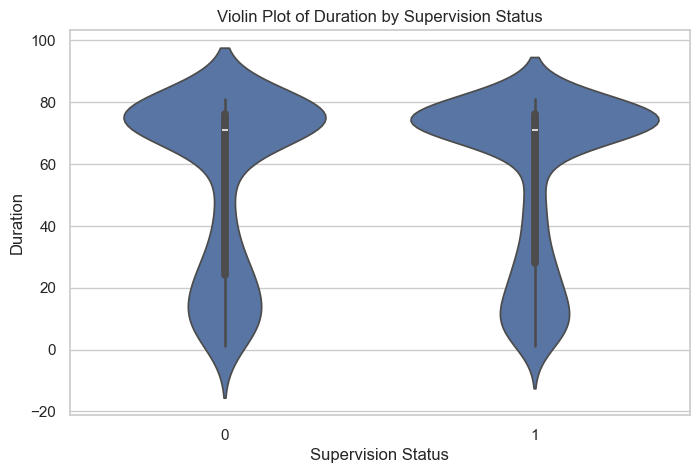

In [69]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=df, x="super", y="durat")

plt.title("Violin Plot of Duration by Supervision Status")
plt.xlabel("Supervision Status")
plt.ylabel("Duration")
plt.show()

In [70]:
pair = df[["age", "durat"]].dropna()

pearson = pearsonr(pair["age"], pair["durat"])
spearman = spearmanr(pair["age"], pair["durat"])

comparison = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [pearson.statistic, spearman.statistic],
    "P Value": [pearson.pvalue, spearman.pvalue]
})

display(comparison)

,Method,Correlation,P Value
0,Pearson,0.097341,0.000211
1,Spearman,0.090260,0.000592


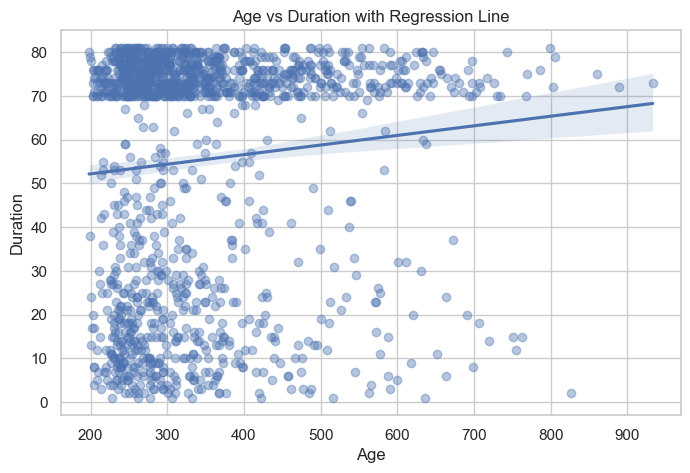

In [71]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="age",
    y="durat",
    scatter_kws={"alpha": 0.4}
)

plt.title("Age vs Duration with Regression Line")
plt.xlabel("Age")
plt.ylabel("Duration")
plt.show()

In [72]:
grouped = df.groupby(
    ["super", "married"],
    observed=False
)["durat"].agg(["mean", "std", "count"])

display(grouped)

mean        std  count
super married                             
0     0        52.324859  28.740198    354
      1        62.681818  23.195097     88
1     0        54.713296  27.646261    722
      1        58.615658  25.022311    281

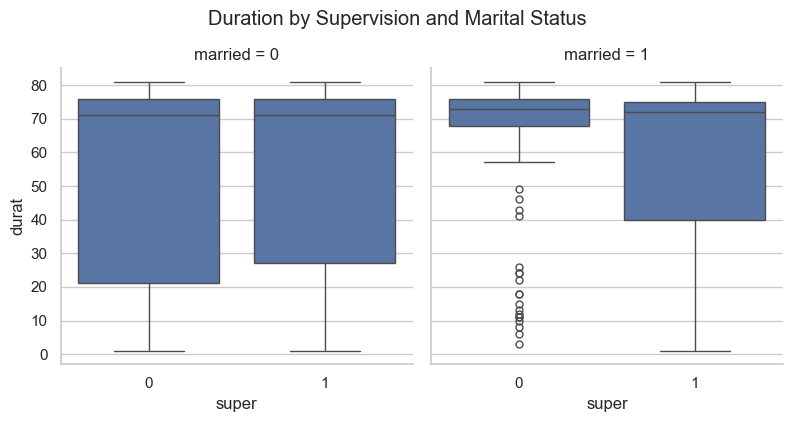

In [73]:
sns.catplot(
    data=df,
    x="super",
    y="durat",
    col="married",
    kind="box",
    height=4,
    aspect=1
)

plt.suptitle("Duration by Supervision and Marital Status", y=1.05)
plt.show()

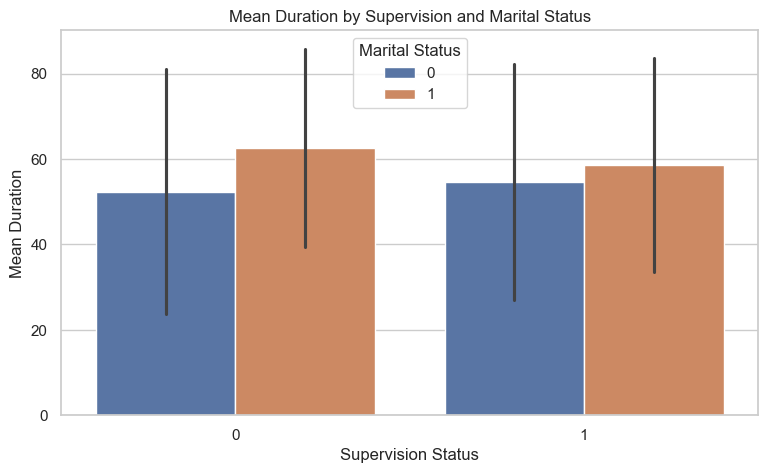

In [74]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="super",
    y="durat",
    hue="married",
    errorbar="sd"
)

plt.title("Mean Duration by Supervision and Marital Status")
plt.xlabel("Supervision Status")
plt.ylabel("Mean Duration")
plt.legend(title="Marital Status")
plt.show()

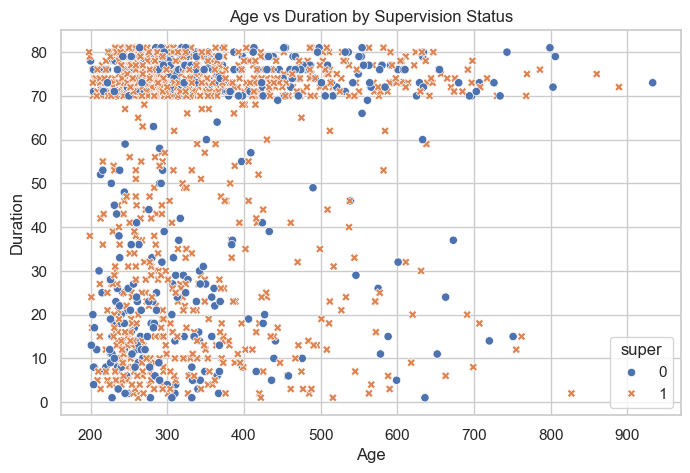

In [75]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="durat",
    hue="super",
    style="super"
)

plt.title("Age vs Duration by Supervision Status")
plt.xlabel("Age")
plt.ylabel("Duration")
plt.show()

In [76]:
for category, group in df.groupby("super", observed=False):
    pair = group[["age", "durat"]].dropna()

    if len(pair) >= 2:
        print("Supervision Status:", category)
        display(pair.corr())

Supervision Status: 0


,age,durat
age,1.000000,0.190425
durat,0.190425,1.000000


Supervision Status: 1


,age,durat
age,1.000000,0.051505
durat,0.051505,1.000000


In [77]:
correlation = df.select_dtypes(include=np.number).corr()

display(correlation)

,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,rules,age,tserved,follow,durat,cens,ldurat
rownames,1.000000,0.007924,-0.039666,0.021276,0.016346,-0.037315,0.011387,-0.022299,0.011054,-0.022137,-0.012833,0.021976,0.012968,-0.029848,0.021090,0.016048,-0.019343,0.004572,-0.033635
black,0.007924,1.000000,-0.119024,-0.156285,0.043344,-0.041311,0.088760,0.033310,0.068255,0.077961,-0.011525,0.106432,0.024131,-0.055505,0.086123,0.002392,-0.111381,-0.120303,-0.095334
alcohol,-0.039666,-0.119024,1.000000,-0.008664,-0.008551,0.099898,-0.165529,-0.074679,-0.145018,-0.023811,0.164754,-0.056998,-0.088308,0.216219,-0.107901,-0.190146,-0.080663,-0.056862,-0.082960
drugs,0.021276,-0.156285,-0.008664,1.000000,-0.078066,-0.041239,-0.051034,-0.013949,-0.066358,0.024496,0.060881,-0.084892,0.043175,0.061703,-0.011459,0.077096,-0.040406,-0.048850,-0.032267
super,0.016346,0.043344,-0.008551,-0.078066,1.000000,0.085659,0.200182,0.152222,0.129495,0.103999,-0.112863,0.035364,-0.096886,-0.042550,0.103591,-0.049560,0.023972,0.025201,0.025595
married,-0.037315,-0.041311,0.099898,-0.041239,0.085659,1.000000,0.003641,0.160350,-0.036331,0.037710,0.029882,-0.068399,-0.087447,0.236069,-0.022882,-0.037581,0.090412,0.081528,0.098069
felon,0.011387,0.088760,-0.165529,-0.051034,0.200182,0.003641,1.000000,0.223777,0.702794,0.310693,0.033458,0.038543,0.228570,-0.019280,0.494381,0.002062,-0.015081,-0.004814,-0.010590
workprg,-0.022299,0.033310,-0.074679,-0.013949,0.152222,0.160350,0.223777,1.000000,0.146051,0.093841,0.106543,0.005669,0.016547,0.131652,0.211314,0.068093,-0.002349,-0.017966,-0.000540
property,0.011054,0.068255,-0.145018,-0.066358,0.129495,-0.036331,0.702794,0.146051,1.000000,-0.138681,0.058580,0.056951,0.243495,-0.075195,0.357003,0.049488,-0.077302,-0.063493,-0.078903
person,-0.022137,0.077961,-0.023811,0.024496,0.103999,0.037710,0.310693,0.093841,-0.138681,1.000000,0.015948,-0.120036,0.033192,0.119912,0.263908,-0.053893,0.005344,0.008970,0.012885


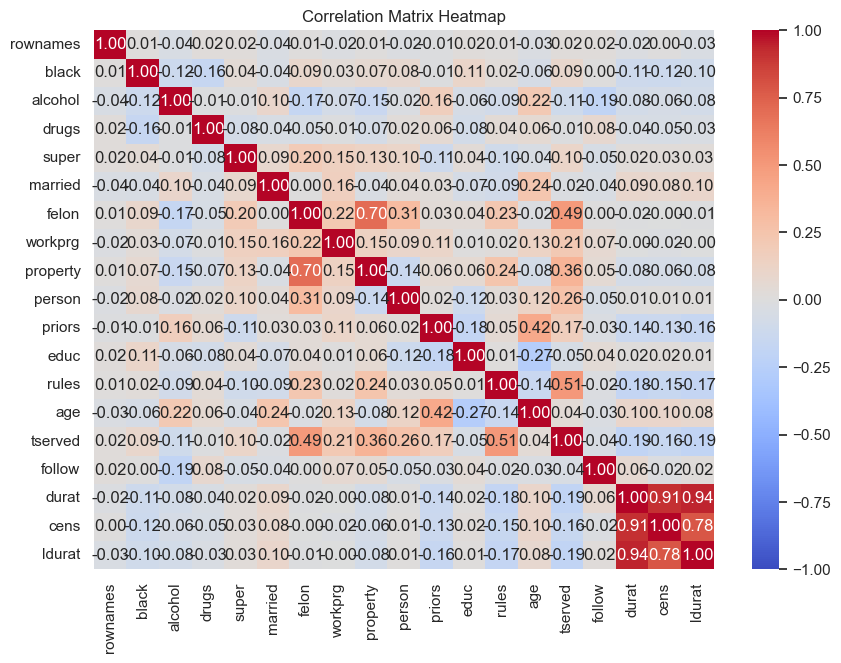

In [78]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Matrix Heatmap")
plt.show()

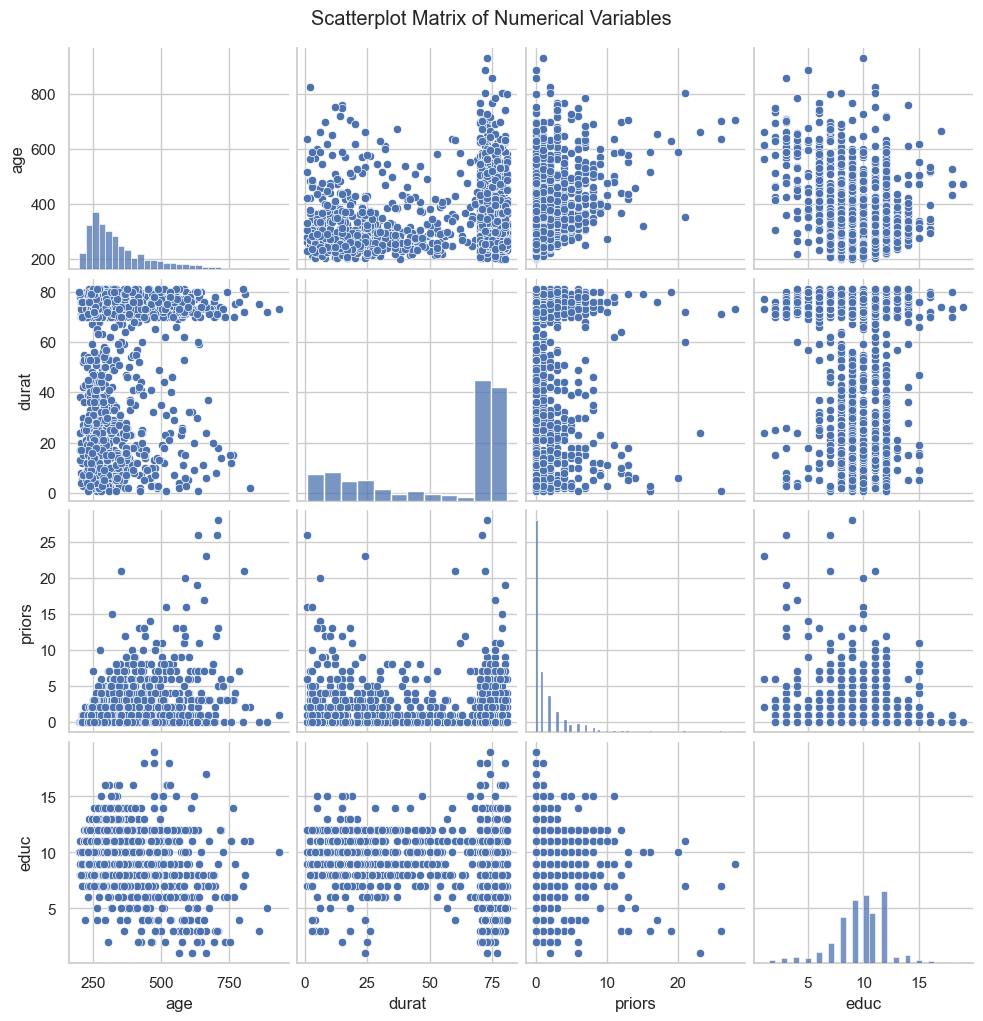

In [79]:
pairdata = df[["age", "durat", "priors", "educ"]].dropna()

sns.pairplot(pairdata, diag_kind="hist")

plt.suptitle("Scatterplot Matrix of Numerical Variables", y=1.02)
plt.show()

In [80]:
numData = df.select_dtypes(include="number").dropna()

numData = numData.loc[:, numData.nunique() > 1]

print("Numerical columns used for clustering:")
print(numData.columns.tolist())

print("\nDataset shape:", numData.shape)

Numerical columns used for clustering:
['rownames', 'black', 'alcohol', 'drugs', 'super', 'married', 'felon', 'workprg', 'property', 'person', 'priors', 'educ', 'rules', 'age', 'tserved', 'follow', 'durat', 'cens', 'ldurat']

Dataset shape: (1445, 19)


In [81]:
scaler = StandardScaler()
scaledData = scaler.fit_transform(numData)

print("Standardized data shape:", scaledData.shape)

Standardized data shape: (1445, 19)


In [82]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(scaledData)

clusterData = numData.copy()
clusterData["Cluster"] = clusters

print("Cluster centers:")
print(kmeans.cluster_centers_)

print("\nNumber of observations in each cluster:")
print(clusterData["Cluster"].value_counts().sort_index())

Cluster centers:
[[-0.0087521  -0.0902822  -0.04238941 -0.04397082  0.01863157  0.07633107
  -0.0154243  -0.00904485 -0.06345136  0.00822748 -0.09843371  0.01207419
  -0.12275846  0.08899711 -0.13104899 -0.01710834  0.70060921  0.71501936
   0.60993323]
 [ 0.01556864  0.16059814  0.07540424  0.07821733 -0.03314269 -0.13578123
   0.02743746  0.01608939  0.11287021 -0.01463542  0.17509842 -0.02147813
   0.21836841 -0.15831216  0.23311599  0.03043311 -1.246276   -1.27190944
  -1.08497738]]

Number of observations in each cluster:
Cluster
0    925
1    520
Name: count, dtype: int64


In [83]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(scaledData)

clusterData = numData.copy()
clusterData["Cluster"] = clusters

print("Cluster centers:")
print(kmeans.cluster_centers_)

print("\nNumber of observations in each cluster:")
print(clusterData["Cluster"].value_counts().sort_index())

Cluster centers:
[[-0.0087521  -0.0902822  -0.04238941 -0.04397082  0.01863157  0.07633107
  -0.0154243  -0.00904485 -0.06345136  0.00822748 -0.09843371  0.01207419
  -0.12275846  0.08899711 -0.13104899 -0.01710834  0.70060921  0.71501936
   0.60993323]
 [ 0.01556864  0.16059814  0.07540424  0.07821733 -0.03314269 -0.13578123
   0.02743746  0.01608939  0.11287021 -0.01463542  0.17509842 -0.02147813
   0.21836841 -0.15831216  0.23311599  0.03043311 -1.246276   -1.27190944
  -1.08497738]]

Number of observations in each cluster:
Cluster
0    925
1    520
Name: count, dtype: int64


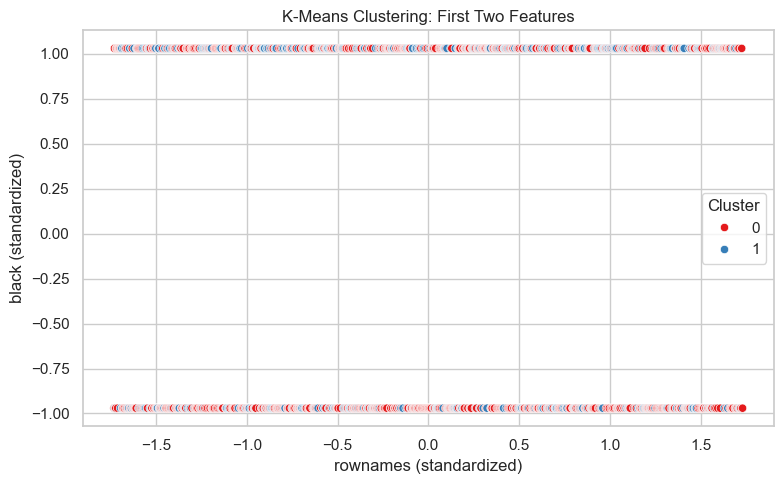

In [84]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=scaledData[:, 0],
    y=scaledData[:, 1],
    hue=clusters,
    palette="Set1"
)
plt.title("K-Means Clustering: First Two Features")
plt.xlabel(numData.columns[0] + " (standardized)")
plt.ylabel(numData.columns[1] + " (standardized)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [85]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaledData)
    wcss.append(model.inertia_)

print(pd.DataFrame({"Number of Clusters": range(1, 11), "WCSS": wcss}))

   Number of Clusters          WCSS
0                   1  27455.000000
1                   2  23735.684247
2                   3  21901.025547
3                   4  20315.005373
4                   5  19312.137451
5                   6  18347.913936
6                   7  17721.452989
7                   8  17116.713633
8                   9  16627.060826
9                  10  16128.191808


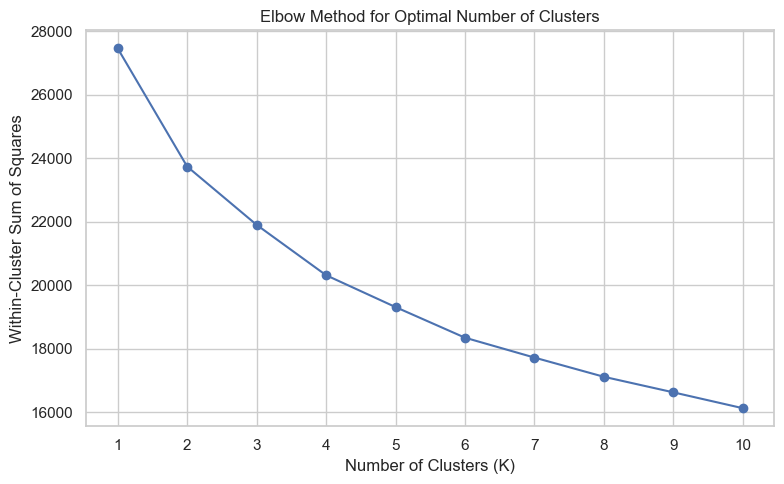

In [86]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

In [87]:
linkageMatrix = linkage(scaledData, method="ward", metric="euclidean")

print("Linkage matrix shape:", linkageMatrix.shape)
print(linkageMatrix[:5])

Linkage matrix shape: (1444, 4)
[[7.16000000e+02 7.51000000e+02 8.55179240e-02 2.00000000e+00]
 [3.50000000e+02 3.99000000e+02 1.48532738e-01 2.00000000e+00]
 [4.80000000e+02 5.49000000e+02 2.23624567e-01 2.00000000e+00]
 [1.13700000e+03 1.16100000e+03 2.57847783e-01 2.00000000e+00]
 [1.06400000e+03 1.11100000e+03 3.31286206e-01 2.00000000e+00]]


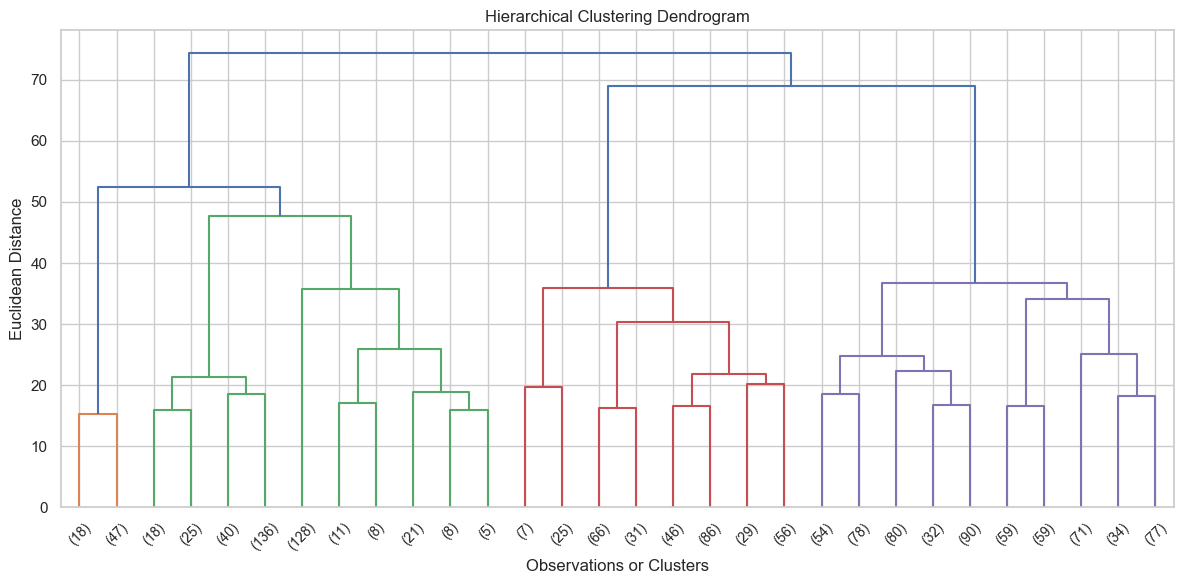

In [88]:
plt.figure(figsize=(12, 6))
dendrogram(linkageMatrix, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Observations or Clusters")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

In [89]:
hierClusters = fcluster(linkageMatrix, t=3, criterion="maxclust")

hierData = numData.copy()
hierData["Cluster"] = hierClusters

print("Number of observations in each hierarchical cluster:")
print(hierData["Cluster"].value_counts().sort_index())

print("\nFirst five observations:")
print(hierData.head())

Number of observations in each hierarchical cluster:
Cluster
1    465
2    346
3    634
Name: count, dtype: int64

First five observations:
   rownames  black  alcohol  drugs  super  married  felon  workprg  property  person  priors  educ  rules  age  \
0         1      0        1      0      1        1      0        1         0       0       0     7      2  441   
1         2      1        0      0      1        0      1        1         1       0       0    12      0  307   
2         3      0        0      0      0        0      0        1         1       0       0     9      5  262   
3         4      0        0      1      1        0      1        1         1       0       2     9      3  253   
4         5      0        0      1      1        0      0        0         0       0       0     9      0  244   

   tserved  follow  durat  cens    ldurat  Cluster  
0       30      72     72     1  4.276666        3  
1       19      75     75     1  4.317488        1  
2       27      

In [90]:
comparison = pd.DataFrame({
    "K-Means": pd.Series(clusters).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierClusters).value_counts().sort_index()
}).fillna(0).astype(int)

print("Cluster size comparison:")
print(comparison)

Cluster size comparison:
   K-Means  Hierarchical
0      925             0
1      520           465
2        0           346
3        0           634


In [91]:
pcaData = df.select_dtypes(include="number").copy()

pcaData = pcaData.replace([np.inf, -np.inf], np.nan)
pcaData = pcaData.dropna()
pcaData = pcaData.loc[:, pcaData.nunique() > 1]

print("Data shape:", pcaData.shape)
print("\nNumerical columns:")
print(pcaData.columns.tolist())

Data shape: (1445, 19)

Numerical columns:
['rownames', 'black', 'alcohol', 'drugs', 'super', 'married', 'felon', 'workprg', 'property', 'person', 'priors', 'educ', 'rules', 'age', 'tserved', 'follow', 'durat', 'cens', 'ldurat']


In [92]:
pcaScaler = StandardScaler()
scaledPcaData = pcaScaler.fit_transform(pcaData)

pcaModel = PCA()
pcaScores = pcaModel.fit_transform(scaledPcaData)

print("Explained variance ratio:")
print(pcaModel.explained_variance_ratio_)

print("\nCumulative explained variance:")
print(np.cumsum(pcaModel.explained_variance_ratio_))

Explained variance ratio:
[0.16234343 0.12439152 0.10001924 0.07056068 0.06189268 0.06037514
 0.05575796 0.05264589 0.04786318 0.04517371 0.04098819 0.04063528
 0.03787363 0.03361071 0.02510753 0.01947    0.01126998 0.00880803
 0.00121321]

Cumulative explained variance:
[0.16234343 0.28673495 0.38675419 0.45731487 0.51920755 0.57958269
 0.63534066 0.68798654 0.73584972 0.78102344 0.82201162 0.8626469
 0.90052053 0.93413124 0.95923878 0.97870878 0.98997876 0.99878679
 1.        ]


In [93]:
pcaSummary = pd.DataFrame({
    "Principal Component": [
        "PC" + str(i + 1) for i in range(len(pcaModel.explained_variance_ratio_))
    ],
    "Explained Variance (%)": pcaModel.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)": np.cumsum(pcaModel.explained_variance_ratio_) * 100
})

print(pcaSummary.round(2))

   Principal Component  Explained Variance (%)  Cumulative Variance (%)
0                  PC1                   16.23                    16.23
1                  PC2                   12.44                    28.67
2                  PC3                   10.00                    38.68
3                  PC4                    7.06                    45.73
4                  PC5                    6.19                    51.92
5                  PC6                    6.04                    57.96
6                  PC7                    5.58                    63.53
7                  PC8                    5.26                    68.80
8                  PC9                    4.79                    73.58
9                 PC10                    4.52                    78.10
10                PC11                    4.10                    82.20
11                PC12                    4.06                    86.26
12                PC13                    3.79                  

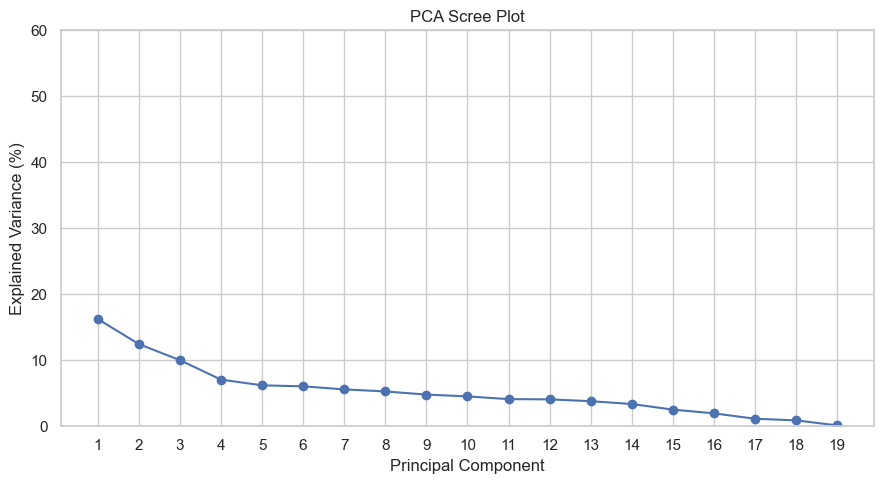

In [94]:
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(pcaModel.explained_variance_ratio_) + 1),
    pcaModel.explained_variance_ratio_ * 100,
    marker="o"
)
plt.title("PCA Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.xticks(range(1, len(pcaModel.explained_variance_ratio_) + 1))
plt.ylim(0, 60)
plt.grid(True)
plt.tight_layout()
plt.show()

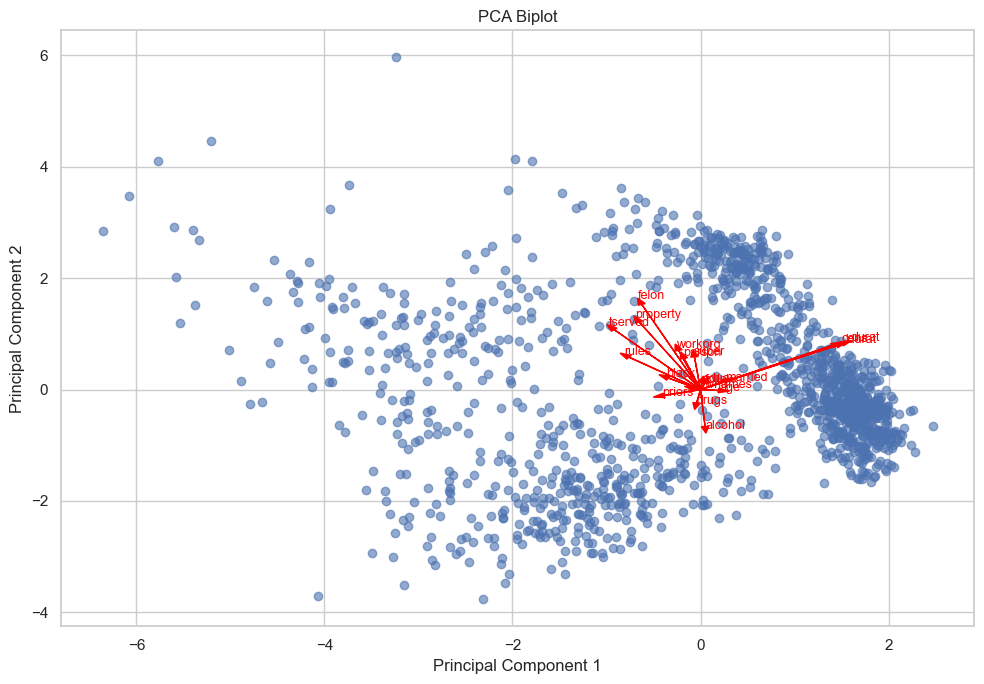

In [95]:
pcaTwo = PCA(n_components=2)
scoresTwo = pcaTwo.fit_transform(scaledPcaData)

loadings = pcaTwo.components_.T

plt.figure(figsize=(10, 7))
plt.scatter(scoresTwo[:, 0], scoresTwo[:, 1], alpha=0.6)

for i, name in enumerate(pcaData.columns):
    plt.arrow(
        0, 0,
        loadings[i, 0] * 3,
        loadings[i, 1] * 3,
        color="red",
        head_width=0.08
    )
    plt.text(
        loadings[i, 0] * 3.2,
        loadings[i, 1] * 3.2,
        name,
        color="red",
        fontsize=9
    )

plt.title("PCA Biplot")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()

In [96]:
scoreData = pd.DataFrame(
    pcaScores,
    columns=["PC" + str(i + 1) for i in range(pcaScores.shape[1])],
    index=pcaData.index
)

print("PCA scores:")
print(scoreData.head())

PCA scores:
        PC1       PC2       PC3       PC4       PC5       PC6       PC7       PC8       PC9      PC10      PC11  \
0  1.303317  0.094876  2.242490  1.109797 -0.753325 -0.899894 -1.020229 -1.857180  1.078989 -0.773530 -0.588695   
1  0.314699  2.496066 -1.046668  1.115349  0.622840 -0.803167  0.644361 -1.431080 -1.112806  0.830570  0.280405   
2 -2.913071 -0.399535 -0.970566 -1.449154  1.326178 -0.426135  0.246171 -2.362139  0.419044 -0.988556 -1.414312   
3 -2.671684  1.329111 -0.116270 -1.026323  0.940766 -0.098724 -1.729387 -1.986003 -0.909325  0.505022  0.324539   
4  1.966879 -0.480510 -0.942532 -1.325528  0.915507  1.117080 -1.119354 -1.822267 -1.186337  0.312914  0.099952   

       PC12      PC13      PC14      PC15      PC16      PC17      PC18      PC19  
0  0.313485  0.857083  0.923620  0.329163  0.328458  0.181561 -0.052373 -0.026017  
1  0.437868 -0.330062  0.436587  0.192916 -0.096668  0.218113 -0.033265 -0.004018  
2 -0.262291 -0.490142  0.798320  0.363155 -0.

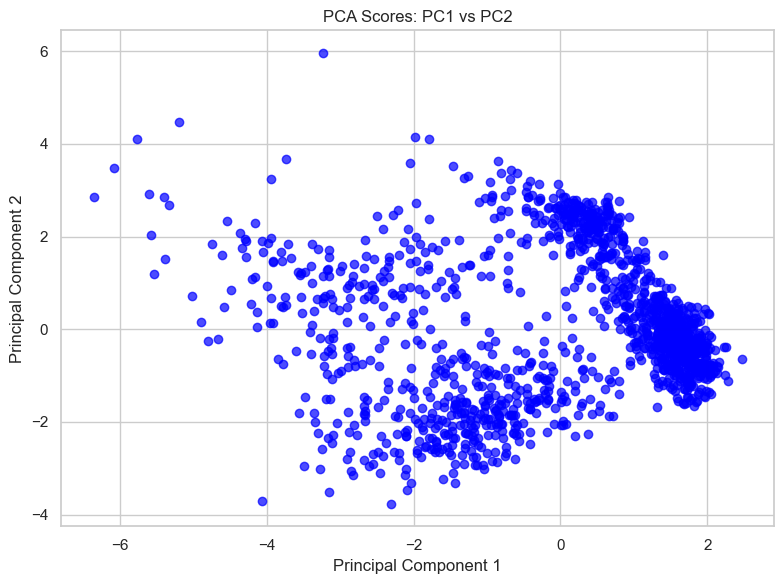

In [97]:
plt.figure(figsize=(8, 6))
plt.scatter(
    scoreData["PC1"],
    scoreData["PC2"],
    color="blue",
    marker="o",
    alpha=0.7
)
plt.title("PCA Scores: PC1 vs PC2")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()

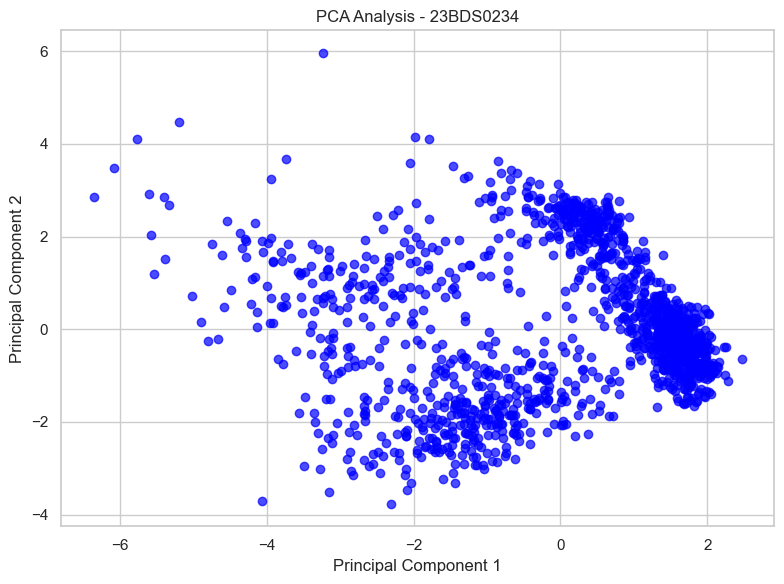

In [99]:
plt.figure(figsize=(8, 6))
plt.scatter(
    scoreData["PC1"],
    scoreData["PC2"],
    color="blue",
    marker="o",
    alpha=0.7
)
plt.title("PCA Analysis - 23BDS0234")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()

In [100]:
print(numData.describe().round(3))

       rownames     black   alcohol     drugs     super   married     felon   workprg  property    person    priors  \
count   1445.00  1445.000  1445.000  1445.000  1445.000  1445.000  1445.000  1445.000  1445.000  1445.000  1445.000   
mean     723.00     0.485     0.210     0.242     0.694     0.255     0.314     0.465     0.255     0.053     1.432   
std      417.28     0.500     0.407     0.428     0.461     0.436     0.464     0.499     0.436     0.225     2.850   
min        1.00     0.000     0.000     0.000     0.000     0.000     0.000     0.000     0.000     0.000     0.000   
25%      362.00     0.000     0.000     0.000     0.000     0.000     0.000     0.000     0.000     0.000     0.000   
50%      723.00     0.000     0.000     0.000     1.000     0.000     0.000     0.000     0.000     0.000     0.000   
75%     1084.00     1.000     0.000     0.000     1.000     1.000     1.000     1.000     1.000     0.000     2.000   
max     1445.00     1.000     1.000     1.000   

In [101]:
pcaData = numData.dropna()

scaler = StandardScaler()
dataScaled = scaler.fit_transform(pcaData)

print(pd.DataFrame(dataScaled, columns=pcaData.columns).head())

   rownames     black   alcohol     drugs     super   married     felon   workprg  property    person    priors  \
0 -1.730853 -0.970672  1.941385 -0.564297  0.663836  1.707627 -0.676848  1.072519 -0.584542 -0.237248 -0.502494   
1 -1.728455  1.030214 -0.515096 -0.564297  0.663836 -0.585608  1.477437  1.072519  1.710740 -0.237248 -0.502494   
2 -1.726058 -0.970672 -0.515096 -0.564297 -1.506397 -0.585608 -0.676848  1.072519  1.710740 -0.237248 -0.502494   
3 -1.723661 -0.970672 -0.515096  1.772118  0.663836 -0.585608  1.477437  1.072519  1.710740 -0.237248  0.199395   
4 -1.721263 -0.970672 -0.515096  1.772118  0.663836 -0.585608 -0.676848 -0.932384 -0.584542 -0.237248 -0.502494   

       educ     rules       age   tserved    follow     durat      cens    ldurat  
0 -1.107223  0.354976  0.789729  0.516211 -0.824683  0.609332  0.786219  0.574783  
1  0.941352 -0.516630 -0.317630 -0.008685  0.032631  0.719269  0.786219  0.618928  
2 -0.287793  1.662385 -0.689504  0.373058  1.747261 -1.69

In [102]:
pcaModel = PCA()
pcaScores = pcaModel.fit_transform(dataScaled)

print("PCA completed successfully")
print("Number of principal components:", pcaModel.n_components_)

PCA completed successfully
Number of principal components: 19


In [103]:
varianceTable = pd.DataFrame({
    "Principal Component": [
        "PC" + str(i + 1)
        for i in range(len(pcaModel.explained_variance_ratio_))
    ],
    "Proportion of Variance": pcaModel.explained_variance_ratio_,
    "Percentage of Variance": pcaModel.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)": np.cumsum(
        pcaModel.explained_variance_ratio_
    ) * 100
})

print(varianceTable.round(4))

   Principal Component  Proportion of Variance  Percentage of Variance  Cumulative Variance (%)
0                  PC1                  0.1623                 16.2343                  16.2343
1                  PC2                  0.1244                 12.4392                  28.6735
2                  PC3                  0.1000                 10.0019                  38.6754
3                  PC4                  0.0706                  7.0561                  45.7315
4                  PC5                  0.0619                  6.1893                  51.9208
5                  PC6                  0.0604                  6.0375                  57.9583
6                  PC7                  0.0558                  5.5758                  63.5341
7                  PC8                  0.0526                  5.2646                  68.7987
8                  PC9                  0.0479                  4.7863                  73.5850
9                 PC10                  

In [104]:
cumulativeVariance = np.cumsum(pcaModel.explained_variance_ratio_)
requiredComponents = np.argmax(cumulativeVariance >= 0.80) + 1

print("Minimum components required:", requiredComponents)
print(
    "Cumulative variance explained:",
    round(cumulativeVariance[requiredComponents - 1] * 100, 2),
    "%"
)

Minimum components required: 11
Cumulative variance explained: 82.2 %


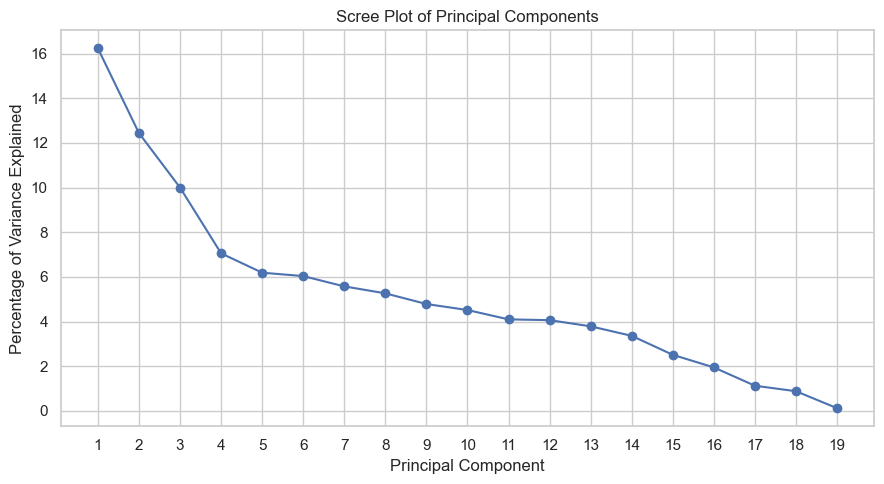

In [105]:
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(pcaModel.explained_variance_ratio_) + 1),
    pcaModel.explained_variance_ratio_ * 100,
    marker="o"
)
plt.title("Scree Plot of Principal Components")
plt.xlabel("Principal Component")
plt.ylabel("Percentage of Variance Explained")
plt.xticks(range(1, len(pcaModel.explained_variance_ratio_) + 1))
plt.grid(True)
plt.tight_layout()
plt.show()

In [106]:
loadings = pd.DataFrame(
    pcaModel.components_.T,
    index=pcaData.columns,
    columns=[
        "PC" + str(i + 1)
        for i in range(pcaModel.n_components_)
    ]
)

print("Loadings for PC1 and PC2:")
print(loadings[["PC1", "PC2"]].round(4))

Loadings for PC1 and PC2:
             PC1     PC2
rownames -0.0193  0.0067
black    -0.1134  0.0687
alcohol   0.0162 -0.2208
drugs    -0.0139 -0.0798
super    -0.0215  0.1959
married   0.0807  0.0494
felon    -0.2082  0.5099
workprg  -0.0775  0.2348
property -0.2174  0.4045
person   -0.0586  0.1872
priors   -0.1289 -0.0349
educ      0.0051  0.0410
rules    -0.2534  0.1940
age       0.0633 -0.0053
tserved  -0.3060  0.3587
follow    0.0146  0.0390
durat     0.5011  0.2747
cens      0.4674  0.2645
ldurat    0.4806  0.2633


In [107]:
print("Strongest contributors to PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False))

print("\nStrongest contributors to PC2:")
print(loadings["PC2"].abs().sort_values(ascending=False))

Strongest contributors to PC1:
durat       0.501123
ldurat      0.480643
cens        0.467380
tserved     0.305963
rules       0.253449
property    0.217407
felon       0.208201
priors      0.128868
black       0.113415
married     0.080670
workprg     0.077524
age         0.063264
person      0.058576
super       0.021507
rownames    0.019333
alcohol     0.016175
follow      0.014560
drugs       0.013937
educ        0.005066
Name: PC1, dtype: float64

Strongest contributors to PC2:
felon       0.509902
property    0.404454
tserved     0.358682
durat       0.274743
cens        0.264549
ldurat      0.263272
workprg     0.234827
alcohol     0.220810
super       0.195914
rules       0.194020
person      0.187210
drugs       0.079752
black       0.068742
married     0.049363
educ        0.040955
follow      0.039008
priors      0.034851
rownames    0.006685
age         0.005254
Name: PC2, dtype: float64


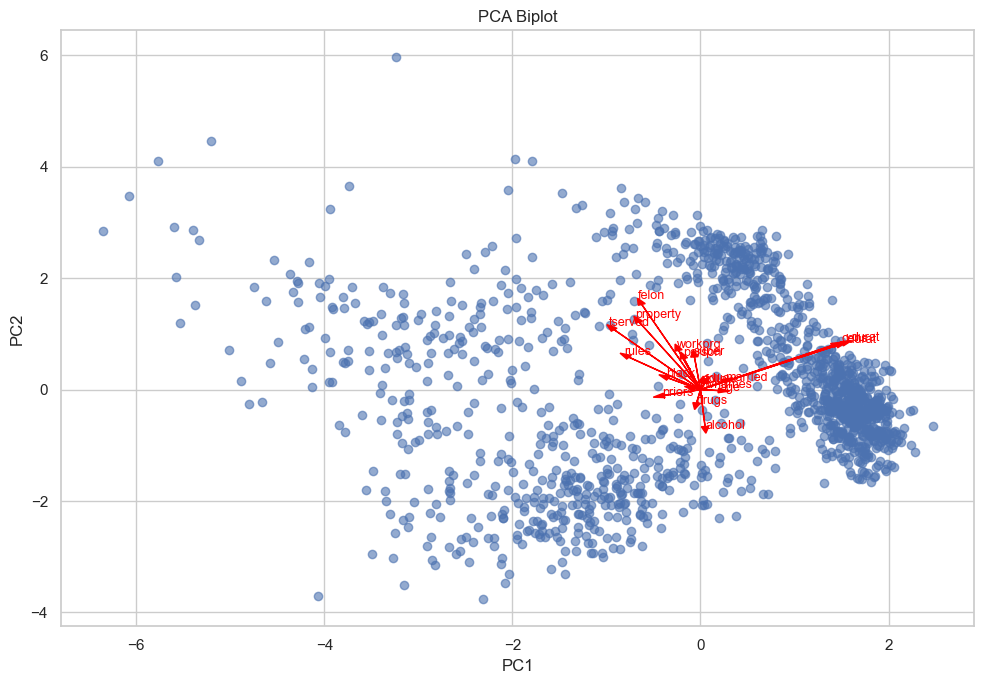

In [108]:
pcaTwo = PCA(n_components=2)
scoresTwo = pcaTwo.fit_transform(dataScaled)
loadingsTwo = pcaTwo.components_.T

plt.figure(figsize=(10, 7))
plt.scatter(scoresTwo[:, 0], scoresTwo[:, 1], alpha=0.6)

for i, name in enumerate(pcaData.columns):
    plt.arrow(
        0, 0,
        loadingsTwo[i, 0] * 3,
        loadingsTwo[i, 1] * 3,
        color="red",
        head_width=0.08
    )
    plt.text(
        loadingsTwo[i, 0] * 3.2,
        loadingsTwo[i, 1] * 3.2,
        name,
        color="red",
        fontsize=9
    )

plt.title("PCA Biplot")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.tight_layout()
plt.show()

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [110]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1445
Number of columns: 19


In [112]:
numericData = df.select_dtypes(include="number").copy()
numericData = numericData.replace([np.inf, -np.inf], np.nan)
numericData = numericData.dropna()
numericData = numericData.loc[:, numericData.nunique() > 1]

scaler = StandardScaler()
data_scaled = scaler.fit_transform(numericData)

print("Standardized data shape:", data_scaled.shape)

Standardized data shape: (1445, 19)


In [113]:
pcaModel = PCA()
pcaResults = pcaModel.fit_transform(data_scaled)

pcaSummary = pd.DataFrame({
    "Principal Component": [
        "PC" + str(i + 1)
        for i in range(len(pcaModel.explained_variance_ratio_))
    ],
    "Standard Deviation": np.sqrt(pcaModel.explained_variance_),
    "Proportion of Variance": pcaModel.explained_variance_ratio_,
    "Cumulative Proportion": np.cumsum(
        pcaModel.explained_variance_ratio_
    )
})

print(pcaSummary.round(4))

   Principal Component  Standard Deviation  Proportion of Variance  Cumulative Proportion
0                  PC1              1.7569                  0.1623                 0.1623
1                  PC2              1.5379                  0.1244                 0.2867
2                  PC3              1.3790                  0.1000                 0.3868
3                  PC4              1.1583                  0.0706                 0.4573
4                  PC5              1.0848                  0.0619                 0.5192
5                  PC6              1.0714                  0.0604                 0.5796
6                  PC7              1.0296                  0.0558                 0.6353
7                  PC8              1.0005                  0.0526                 0.6880
8                  PC9              0.9540                  0.0479                 0.7358
9                 PC10              0.9268                  0.0452                 0.7810
10        

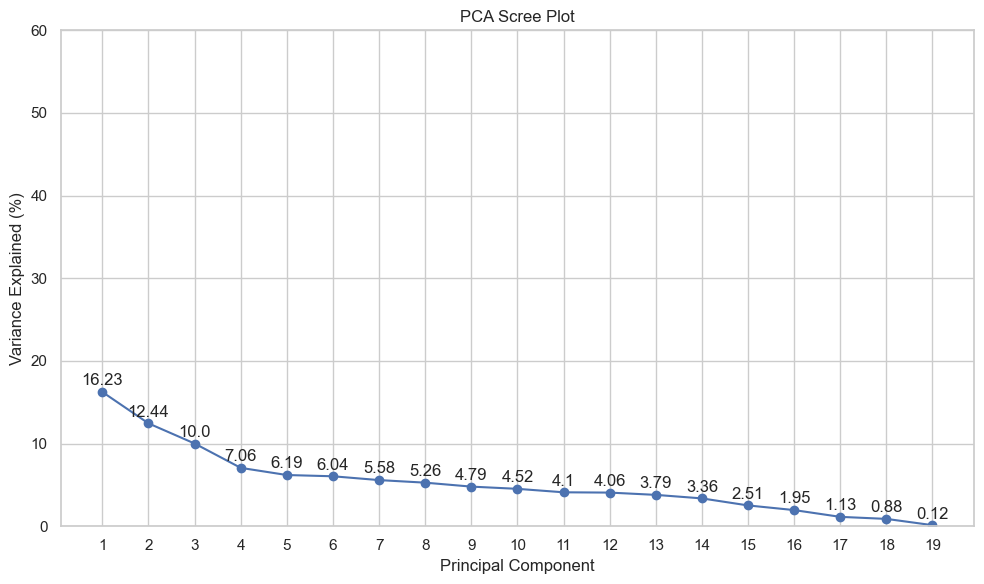

In [114]:
variancePercent = pcaModel.explained_variance_ratio_ * 100

plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(variancePercent) + 1),
    variancePercent,
    marker="o"
)

for i, value in enumerate(variancePercent):
    plt.text(i + 1, value + 0.8, str(round(value, 2)), ha="center")

plt.title("PCA Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Variance Explained (%)")
plt.ylim(0, 60)
plt.xticks(range(1, len(variancePercent) + 1))
plt.grid(True)
plt.tight_layout()
plt.show()

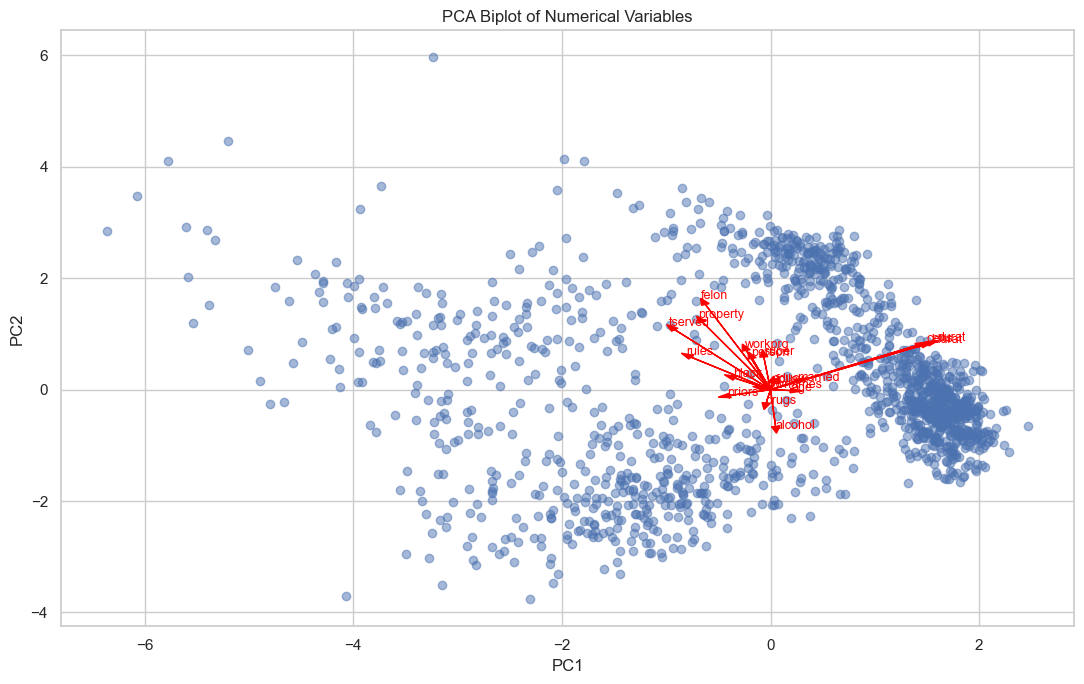

In [115]:
pcaTwo = PCA(n_components=2)
scoresTwo = pcaTwo.fit_transform(data_scaled)
loadingsTwo = pcaTwo.components_.T

plt.figure(figsize=(11, 7))
plt.scatter(scoresTwo[:, 0], scoresTwo[:, 1], alpha=0.5)

for i, name in enumerate(numericData.columns):
    plt.arrow(
        0, 0,
        loadingsTwo[i, 0] * 3,
        loadingsTwo[i, 1] * 3,
        color="red",
        head_width=0.08
    )
    plt.text(
        loadingsTwo[i, 0] * 3.2,
        loadingsTwo[i, 1] * 3.2,
        name,
        fontsize=9,
        color="red"
    )

plt.title("PCA Biplot of Numerical Variables")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.tight_layout()
plt.show()

In [116]:
pca_scores = pd.DataFrame(
    pcaResults,
    columns=[
        "PC" + str(i + 1)
        for i in range(pcaResults.shape[1])
    ],
    index=numericData.index
)

print(pca_scores.head(6))

        PC1       PC2       PC3       PC4       PC5       PC6       PC7       PC8       PC9      PC10      PC11  \
0  1.303317  0.094876  2.242490  1.109797 -0.753325 -0.899894 -1.020229 -1.857180  1.078989 -0.773530 -0.588695   
1  0.314699  2.496066 -1.046668  1.115349  0.622840 -0.803167  0.644361 -1.431080 -1.112806  0.830570  0.280405   
2 -2.913071 -0.399535 -0.970566 -1.449154  1.326178 -0.426135  0.246171 -2.362139  0.419044 -0.988556 -1.414312   
3 -2.671684  1.329111 -0.116270 -1.026323  0.940766 -0.098724 -1.729387 -1.986003 -0.909325  0.505022  0.324539   
4  1.966879 -0.480510 -0.942532 -1.325528  0.915507  1.117080 -1.119354 -1.822267 -1.186337  0.312914  0.099952   
5  1.405845  0.455356 -1.073409  0.912234  1.078567  0.467275  1.217380 -1.545759 -0.114987  0.891735 -0.777332   

       PC12      PC13      PC14      PC15      PC16      PC17      PC18      PC19  
0  0.313485  0.857083  0.923620  0.329163  0.328458  0.181561 -0.052373 -0.026017  
1  0.437868 -0.330062  0.4

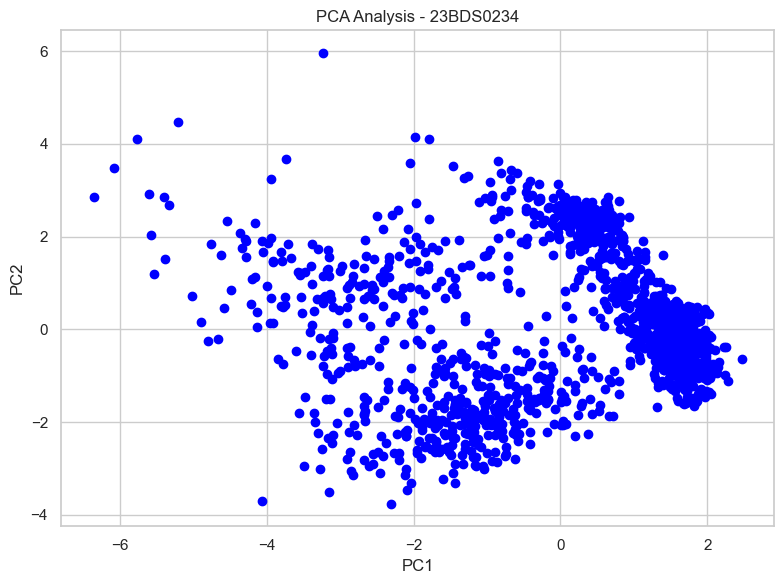

In [118]:
plt.figure(figsize=(8, 6))
plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue",
    marker="o"
)
plt.title("PCA Analysis - 23BDS0234")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.tight_layout()
plt.show()

In [119]:
variance = pcaModel.explained_variance_ratio_
cumulative = np.cumsum(variance)

metrics = pd.DataFrame({
    "Metric": [
        "Total Variance Explained",
        "Components for 80% Variance",
        "Components for 90% Variance",
        "Variance Explained by PC1",
        "Variance Explained by PC2",
        "Variance Explained by First 2 PCs",
        "Reconstruction MSE using 2 PCs"
    ],
    "Value": [
        round(variance.sum() * 100, 2),
        int(np.argmax(cumulative >= 0.80) + 1),
        int(np.argmax(cumulative >= 0.90) + 1),
        round(variance[0] * 100, 2),
        round(variance[1] * 100, 2),
        round(cumulative[1] * 100, 2),
        round(np.mean((data_scaled - PCA(n_components=2).fit_transform(data_scaled) @ PCA(n_components=2).fit(data_scaled).components_) ** 2), 4)
    ]
})

print(metrics.to_string(index=False))

                           Metric    Value
         Total Variance Explained 100.0000
      Components for 80% Variance  11.0000
      Components for 90% Variance  13.0000
        Variance Explained by PC1  16.2300
        Variance Explained by PC2  12.4400
Variance Explained by First 2 PCs  28.6700
   Reconstruction MSE using 2 PCs   0.7133


In [120]:
pcaTwo = PCA(n_components=2)
reducedData = pcaTwo.fit_transform(data_scaled)
reconstructedData = pcaTwo.inverse_transform(reducedData)

reconstructionMSE = np.mean((data_scaled - reconstructedData) ** 2)

print("Reconstruction MSE:", round(reconstructionMSE, 4))
print("Variance retained:", round(pcaTwo.explained_variance_ratio_.sum() * 100, 2), "%")
print("Variance lost:", round((1 - pcaTwo.explained_variance_ratio_.sum()) * 100, 2), "%")

Reconstruction MSE: 0.7133
Variance retained: 28.67 %
Variance lost: 71.33 %
